# Étude progressive des réseaux de neurones sur le jeu de données HAR
## Version 2 : réseaux plus profonds

**Auteur :** Martine Ouedraogo (M2 MALIA, Deep Learning)

**Objectif de ce notebook.** Prolonger la Version 1 (une seule couche cachée) avec des réseaux de 2 à 4 couches cachées. Il reprend **exactement la même préparation des données** que la Version 1 (mêmes 540 variables, mêmes volontaires de validation 1, 3, 15, 25, 27, même standardisation apprise sur l'entraînement seulement), pour que les scores soient comparables.

**Règle :** le jeu de test n'est pas utilisé ici avant l'évaluation finale (5.2). Tous les choix se font sur la validation.

| Partie | Contenu | État |
|---|---|---|
| Préparation | Imports, données, découpage, DataLoaders, fonctions (repris de la V1) | fait |
| 3 | 3.2 Réseaux plus profonds et combinaisons d'activations | en cours |
| 4 | 4.1 Régularisation, 4.2 analyse et configurations retenues | en cours |
| 5 | 5.1 Courbes d'apprentissage ; 5.2 évaluation finale sur le test | 5.1 et 5.2 faits |
| 6 | Interprétabilité : t-SNE / UMAP | fait |
| 7 | Bonus : LayerNorm (7.1), importance des variables (7.2) | en cours |

## Préparation (identique à la Version 1)

> Je reprends ici sans changement le code de la V1 : imports, chargement, suppression des 21 colonnes copies, découpage par volontaire, standardisation, DataLoaders. Les explications et les justifications sont dans la V1 (Partie 1).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)

In [2]:
train = pd.read_csv("HAR/train.csv")
test = pd.read_csv("HAR/test.csv")

# Variables : on enlève subject et Activity, puis les 21 colonnes copies exactes
X_train = train.drop(columns=["subject", "Activity"])
colonnes_copies = set(X_train.columns[X_train.T.duplicated().to_numpy()])
feature_cols = [c for c in X_train.columns if c not in colonnes_copies]
print("Variables conservées :", len(feature_cols))

encoder = LabelEncoder()
encoder.fit(train["Activity"])

# Découpage par volontaire : mêmes 5 volontaires de validation que la V1
volontaires = sorted(train["subject"].unique().tolist())
vol_val = sorted(np.random.RandomState(SEED).choice(volontaires, size=5, replace=False).tolist())
assert vol_val == [1, 3, 15, 25, 27]
masque_val = train["subject"].isin(vol_val)
tr_df, val_df = train[~masque_val], train[masque_val]

X_tr, X_val = tr_df[feature_cols].to_numpy(), val_df[feature_cols].to_numpy()
y_tr, y_val = encoder.transform(tr_df["Activity"]), encoder.transform(val_df["Activity"])

# Standardisation apprise sur l'entraînement seulement
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)
print("Entraînement :", X_tr_s.shape, "| validation :", X_val_s.shape)

Variables conservées : 540
Entraînement : (5551, 540) | validation : (1801, 540)


In [3]:
X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)

BATCH_SIZE = 64
N_ENTREES, N_CLASSES = X_tr_t.shape[1], 6
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=512, shuffle=False)
train_eval_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=512, shuffle=False)
lossfn = nn.CrossEntropyLoss()
N_EPOCHS = 30
SEEDS = [0, 1, 2, 3, 4]


def train_epoch(model, loader, optimizer, lossfn):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        optimizer.zero_grad()
        perte = lossfn(model(X), y)
        perte.backward()
        optimizer.step()
        total_loss += perte.item() * len(y)
    return total_loss / len(loader.dataset)


def evaluate(model, loader, lossfn):
    model.eval()
    total_loss, y_vrai, y_pred = 0.0, [], []
    with torch.no_grad():
        for X, y in loader:
            sortie = model(X)
            total_loss += lossfn(sortie, y).item() * len(y)
            y_pred.append(sortie.argmax(dim=1))
            y_vrai.append(y)
    y_vrai, y_pred = torch.cat(y_vrai).numpy(), torch.cat(y_pred).numpy()
    return (total_loss / len(loader.dataset), accuracy_score(y_vrai, y_pred),
            f1_score(y_vrai, y_pred, average="macro"))


def moy_std(serie, nd=4):
    return f"{serie.mean():.{nd}f} ± {serie.std():.{nd}f}"

# Partie 3 : Extension de l'architecture (suite)

> **Ce qui est demandé dans cette partie :** la 3.1 (taille de la couche cachée) est dans la Version 1. Ici, la 3.2.

## 3.2 Réseaux plus profonds

> **Demandé :** implémenter des réseaux plus profonds (2 à 4 couches cachées). Tester différentes combinaisons de fonctions d'activation dans les couches intermédiaires et comparer les résultats (accuracy, F1-score), en tenant compte du nombre de paramètres et du temps d'entraînement.

Mes étapes : 3.2.1 (réseau à nombre de couches variable), 3.2.2 (configurations testées), 3.2.3 (entraînement avec 5 graines), 3.2.4 (résultats), 3.2.5 (conclusion).

### 3.2.1 Un réseau à nombre de couches variable

Je généralise le réseau de la V1 : on donne la liste des activations, une par couche cachée, et la largeur commune des couches. La longueur de la liste fixe la profondeur. Je prends 128 neurones par couche, la taille retenue en 3.1, et Adam avec le pas 3e-4 de 2.3, pour ne changer que la profondeur et les activations.

In [4]:
class MLPProfond(nn.Module):
    # Entrées -> [Linear -> activation] x profondeur -> Linear (6 scores bruts)
    def __init__(self, n_entrees, largeur, n_classes, activations):
        super().__init__()
        couches, n_in = [], n_entrees
        for act in activations:
            couches += [nn.Linear(n_in, largeur), act()]
            n_in = largeur
        couches.append(nn.Linear(n_in, n_classes))
        self.reseau = nn.Sequential(*couches)

    def forward(self, x):
        return self.reseau(x)


print(MLPProfond(N_ENTREES, 128, N_CLASSES, [nn.ReLU, nn.Tanh, nn.ReLU]))

MLPProfond(
  (reseau): Sequential(
    (0): Linear(in_features=540, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=6, bias=True)
  )
)


### 3.2.2 Configurations testées

Je teste 2, 3 et 4 couches cachées. Pour chaque profondeur je prends les trois activations identiques partout (ReLU, Tanh, Sigmoid), puis quelques mélanges. Le but des mélanges est de voir si une activation différente selon la couche change quelque chose. Je rappelle que le nombre de paramètres dépend seulement de la profondeur, pas de l'activation.

In [5]:
R, T, S = nn.ReLU, nn.Tanh, nn.Sigmoid
CONFIGS = {
    # 1 couche (référence de la V1, 128 neurones)
    "1 : ReLU": [R],
    # 2 couches
    "2 : ReLU-ReLU": [R, R], "2 : Tanh-Tanh": [T, T], "2 : Sigmoid-Sigmoid": [S, S],
    "2 : ReLU-Tanh": [R, T], "2 : Tanh-ReLU": [T, R],
    # 3 couches
    "3 : ReLU-ReLU-ReLU": [R, R, R], "3 : Tanh-Tanh-Tanh": [T, T, T], "3 : Sigmoid-Sigmoid-Sigmoid": [S, S, S],
    "3 : ReLU-ReLU-Tanh": [R, R, T], "3 : Tanh-ReLU-ReLU": [T, R, R], "3 : ReLU-Tanh-ReLU": [R, T, R],
    # 4 couches
    "4 : ReLU x4": [R] * 4, "4 : Tanh x4": [T] * 4, "4 : Sigmoid x4": [S] * 4,
    "4 : ReLU-ReLU-Tanh-Tanh": [R, R, T, T],
}
for nom, acts in CONFIGS.items():
    n = sum(p.numel() for p in MLPProfond(N_ENTREES, 128, N_CLASSES, acts).parameters())
    print(f"{nom:30s} {n:7d} paramètres")

1 : ReLU                         70022 paramètres
2 : ReLU-ReLU                    86534 paramètres
2 : Tanh-Tanh                    86534 paramètres
2 : Sigmoid-Sigmoid              86534 paramètres
2 : ReLU-Tanh                    86534 paramètres
2 : Tanh-ReLU                    86534 paramètres
3 : ReLU-ReLU-ReLU              103046 paramètres
3 : Tanh-Tanh-Tanh              103046 paramètres
3 : Sigmoid-Sigmoid-Sigmoid     103046 paramètres
3 : ReLU-ReLU-Tanh              103046 paramètres
3 : Tanh-ReLU-ReLU              103046 paramètres
3 : ReLU-Tanh-ReLU              103046 paramètres
4 : ReLU x4                     119558 paramètres
4 : Tanh x4                     119558 paramètres
4 : Sigmoid x4                  119558 paramètres
4 : ReLU-ReLU-Tanh-Tanh         119558 paramètres


### 3.2.3 Entraînement avec 5 graines

J'entraîne chaque configuration 30 époques avec les 5 graines (0 à 4), comme en 2.3, et je mesure le temps de chaque entraînement (évaluations à chaque époque comprises). Les temps sont mesurés sur mon ordinateur, ils servent à comparer les configurations entre elles.

In [6]:
def fit_profond(activations, lr=3e-4, n_epochs=N_EPOCHS, largeur=128, seed=SEED):
    torch.manual_seed(seed)
    model = MLPProfond(N_ENTREES, largeur, N_CLASSES, activations)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    for _ in range(n_epochs):
        train_epoch(model, loader, opt, lossfn)
        tl, ta, _ = evaluate(model, train_eval_loader, lossfn)
        vl, va, vf = evaluate(model, val_loader, lossfn)
        for cle, val in zip(hist, (tl, ta, vl, va, vf)):
            hist[cle].append(val)
    return model, hist


lignes, hist_profond = [], {}
for nom, acts in CONFIGS.items():
    n_params = sum(p.numel() for p in MLPProfond(N_ENTREES, 128, N_CLASSES, acts).parameters())
    for graine in SEEDS:
        t0 = time.time()
        _, h = fit_profond(acts, seed=graine)
        duree = time.time() - t0
        hist_profond[(nom, graine)] = h
        lignes.append({"config": nom, "profondeur": len(acts), "paramètres": n_params, "graine": graine,
                       "acc_train": h["train_acc"][-1], "acc_val": h["val_acc"][-1],
                       "f1_val": h["val_f1"][-1], "perte_train": h["train_loss"][-1],
                       "perte_val": h["val_loss"][-1], "temps_s": duree})
profond_df = pd.DataFrame(lignes)
print("Nombre d'entraînements :", len(profond_df))

Nombre d'entraînements : 80


### 3.2.4 Résultats

In [7]:
resume = []
for nom, d in profond_df.groupby("config", sort=False):
    resume.append({"configuration": nom, "paramètres": d["paramètres"].iloc[0],
                   "acc. entraînement": moy_std(d["acc_train"]),
                   "acc. validation": moy_std(d["acc_val"]),
                   "F1 macro validation": moy_std(d["f1_val"]),
                   "temps (s)": f"{d['temps_s'].mean():.1f}"})
tab_profond = pd.DataFrame(resume).set_index("configuration")
tab_profond

,paramètres,acc. entraînement,acc. validation,F1 macro validation,temps (s)
configuration,,,,,
1 : ReLU,70022,0.9955 ± 0.0010,0.9592 ± 0.0030,0.9561 ± 0.0032,1.4
2 : ReLU-ReLU,86534,0.9969 ± 0.0029,0.9578 ± 0.0058,0.9542 ± 0.0065,1.5
2 : Tanh-Tanh,86534,0.9984 ± 0.0019,0.9564 ± 0.0049,0.9520 ± 0.0056,1.6
2 : Sigmoid-Sigmoid,86534,0.9892 ± 0.0009,0.9606 ± 0.0044,0.9572 ± 0.0051,1.6
2 : ReLU-Tanh,86534,0.9986 ± 0.0025,0.9610 ± 0.0051,0.9576 ± 0.0057,1.6
2 : Tanh-ReLU,86534,0.9985 ± 0.0018,0.9550 ± 0.0030,0.9508 ± 0.0034,1.6
3 : ReLU-ReLU-ReLU,103046,0.9948 ± 0.0037,0.9545 ± 0.0041,0.9507 ± 0.0046,1.7
3 : Tanh-Tanh-Tanh,103046,0.9987 ± 0.0013,0.9532 ± 0.0072,0.9487 ± 0.0080,1.9
3 : Sigmoid-Sigmoid-Sigmoid,103046,0.9905 ± 0.0016,0.9479 ± 0.0127,0.9434 ± 0.0143,1.8


Je remarque que le nombre de paramètres ne dépend que de la profondeur (86 534 pour 2 couches, 103 046 pour 3, 119 558 pour 4), pas de l'activation. À paramètres égaux, les performances varient autant à l'intérieur d'une profondeur qu'entre profondeurs : ce n'est donc pas le nombre de paramètres qui explique les différences.

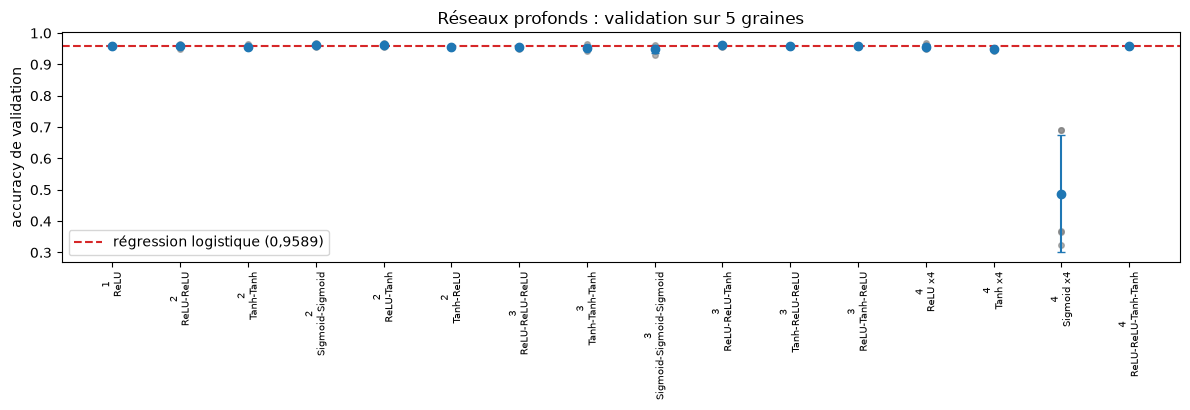

In [8]:
# Accuracy de validation par configuration (points = graines, point bleu = moyenne ± écart-type)
fig, ax = plt.subplots(figsize=(12, 4.2))
noms = list(CONFIGS)
for k, nom in enumerate(noms):
    d = profond_df[profond_df["config"] == nom]
    ax.scatter([k] * len(d), d["acc_val"], color="gray", alpha=0.6, s=16)
    ax.errorbar(k, d["acc_val"].mean(), yerr=d["acc_val"].std(), fmt="o", color="C0", capsize=3)
ax.axhline(0.9589, color="C3", linestyle="--", label="régression logistique (0,9589)")
ax.set_xticks(range(len(noms)))
ax.set_xticklabels([n.replace(" : ", "\n") for n in noms], fontsize=7, rotation=90)
ax.set_ylabel("accuracy de validation")
ax.set_title("Réseaux profonds : validation sur 5 graines")
ax.legend()
plt.tight_layout()
plt.show()

Je constate que presque tous les réseaux sont entre 0,95 et 0,961 de validation, dans les barres d'erreur les uns des autres. Les 3 Sigmoid profonds ressortent : celui à 3 couches a un écart-type de 1,3 point (instable) et celui à 4 couches est loin sous la ligne rouge (0,49). Les réseaux Tanh à 4 couches (0,9484) sont aussi un peu plus bas. À l'entraînement, les réseaux avec Tanh ou un mélange ReLU-Tanh atteignent 99,8 à 99,98 %, plus que ReLU seul : ils surapprennent davantage sans gagner en validation.

In [9]:
# Par profondeur : meilleure moyenne, paramètres, temps, et écart train - validation
par_prof = profond_df.assign(ecart=(profond_df["acc_train"] - profond_df["acc_val"]) * 100)
print(par_prof.groupby("profondeur").agg(paramètres=("paramètres", "first"),
      acc_val=("acc_val", "mean"), f1_val=("f1_val", "mean"),
      ecart_train_val_pts=("ecart", "mean"), temps_s=("temps_s", "mean")).round(4).to_string())

# Règle de 2.3 : une différence est nette si elle dépasse 2 x le plus grand écart-type
def acc_cfg(nom):
    return profond_df[profond_df["config"] == nom]["acc_val"]

def comparer(a, b):
    sa, sb = acc_cfg(a), acc_cfg(b)
    diff, seuil = sa.mean() - sb.mean(), 2 * max(sa.std(), sb.std())
    print(f"{a:28s} contre {b:28s}: {diff * 100:+.2f} pts | seuil {seuil * 100:.2f} | nette ? {'oui' if abs(diff) > seuil else 'non'}")

moyennes = profond_df.groupby("config")["acc_val"].mean()
meilleure = moyennes.idxmax()
print("\nMeilleure moyenne :", meilleure, round(moyennes.max(), 4))
for a, b in [("2 : ReLU-ReLU", "1 : ReLU"), ("3 : ReLU-ReLU-ReLU", "1 : ReLU"), ("4 : ReLU x4", "1 : ReLU"),
             ("3 : ReLU-ReLU-ReLU", "2 : ReLU-ReLU"), ("4 : ReLU x4", "3 : ReLU-ReLU-ReLU"),
             ("3 : ReLU-ReLU-ReLU", "3 : Sigmoid-Sigmoid-Sigmoid"), ("4 : ReLU x4", "4 : Sigmoid x4"),
             ("3 : ReLU-ReLU-ReLU", "3 : Tanh-Tanh-Tanh"), (meilleure, "1 : ReLU")]:
    comparer(a, b)

            paramètres  acc_val  f1_val  ecart_train_val_pts  temps_s
profondeur                                                           
1                70022   0.9592  0.9561               3.6215   1.4110
2                86534   0.9582  0.9544               3.8161   1.5607
3               103046   0.9554  0.9515               4.1814   1.7566
4               119558   0.8376  0.7959               3.0189   2.0016

Meilleure moyenne : 2 : ReLU-Tanh 0.961
2 : ReLU-ReLU                contre 1 : ReLU                    : -0.14 pts | seuil 1.16 | nette ? non
3 : ReLU-ReLU-ReLU           contre 1 : ReLU                    : -0.48 pts | seuil 0.82 | nette ? non
4 : ReLU x4                  contre 1 : ReLU                    : -0.22 pts | seuil 1.40 | nette ? non
3 : ReLU-ReLU-ReLU           contre 2 : ReLU-ReLU               : -0.33 pts | seuil 1.16 | nette ? non
4 : ReLU x4                  contre 3 : ReLU-ReLU-ReLU          : +0.26 pts | seuil 1.40 | nette ? non
3 : ReLU-ReLU-ReLU      

Je remarque que les écarts avec le réseau à une couche sont tous petits et que le seul écart « net » concerne Sigmoid à 4 couches. Pour les profondeurs, la moyenne de la ligne 4 est tirée vers le bas (0,8376) uniquement par ce Sigmoid effondré. Je ne retiens donc pas cette ligne comme représentative de la profondeur 4 : les autres réseaux à 4 couches sont à 0,948 à 0,957. Le temps augmente avec la profondeur (1,4 s, 1,6 s, 1,9 s, 2,8 s).

Le réseau Sigmoid à 4 couches s'effondre avec le pas 3e-4 : il n'apprend même pas le train. Je soupçonne un problème de pas trop petit pour des gradients qui s'affaiblissent à travers les sigmoïdes (cours : gradients qui disparaissent). Je vérifie en refaisant les Sigmoid avec le pas 3e-3, celui qui avait été retenu pour Sigmoid + Adam en 2.2, pour les 3 profondeurs.

In [10]:
lignes = []
for acts, nom in [([S] * 2, "2 : Sigmoid-Sigmoid"), ([S] * 3, "3 : Sigmoid x3"), ([S] * 4, "4 : Sigmoid x4")]:
    for graine in SEEDS:
        _, h = fit_profond(acts, lr=3e-3, seed=graine)
        lignes.append({"config": nom, "graine": graine, "acc_train": h["train_acc"][-1],
                       "acc_val": h["val_acc"][-1], "f1_val": h["val_f1"][-1]})
sig_df = pd.DataFrame(lignes)
for nom, d in sig_df.groupby("config"):
    print(f"{nom:22s} pas 3e-3 | train {moy_std(d['acc_train'])} | val {moy_std(d['acc_val'])} | F1 {moy_std(d['f1_val'])}")
print("\nSigmoid x4, pas 3e-4, accuracy de validation par graine :",
      [round(v, 3) for v in profond_df[profond_df["config"] == "4 : Sigmoid x4"]["acc_val"]])

2 : Sigmoid-Sigmoid    pas 3e-3 | train 1.0000 ± 0.0000 | val 0.9637 ± 0.0058 | F1 0.9608 ± 0.0068
3 : Sigmoid x3         pas 3e-3 | train 0.9940 ± 0.0067 | val 0.9407 ± 0.0058 | F1 0.9353 ± 0.0064
4 : Sigmoid x4         pas 3e-3 | train 0.5998 ± 0.2728 | val 0.5759 ± 0.2420 | F1 0.4723 ± 0.3137

Sigmoid x4, pas 3e-4, accuracy de validation par graine : [0.368, 0.69, 0.324, 0.691, 0.366]


Je constate que Sigmoid à 2 couches avec le pas 3e-3 donne 0,9637 en validation (train à 100 %), la meilleure valeur de ce notebook, mais cela vient d'un pas choisi en plus, donc je ne la compare pas aux autres. Avec 3 couches Sigmoid baisse à 0,9407, puis à 4 couches le réseau n'apprend plus (0,60 en train, très variable selon la graine : écart-type 0,27). Le pas plus grand n'a donc pas sauvé Sigmoid à 4 couches.

### 3.2.5 Conclusion de 3.2

- **Aller plus profond n'aide pas ici.** La meilleure moyenne par profondeur (toutes configurations confondues) est de 0,9592 avec 1 couche, 0,9582 avec 2 et 0,9554 avec 3. Aucune différence avec le réseau à une couche n'est nette selon la règle de 2.3 (écarts de -0,5 à +0,2 point pour des seuils de 0,8 à 1,4 point). Les 70 000 à 120 000 paramètres de plus et le temps d'entraînement doublé (1,4 s contre 2,8 s) ne rapportent rien.
- **Le surapprentissage augmente avec la profondeur** : l'écart train - validation passe de 3,6 à 4,2 points entre 1 et 3 couches. Plusieurs réseaux atteignent 99,9 % en entraînement (ReLU-ReLU-Tanh : 0,9998). C'est un argument pour la régularisation de la Partie 4.
- **Les combinaisons d'activations ne se distinguent pas.** ReLU-Tanh à 2 couches a la meilleure moyenne (0,9610) mais l'écart avec ReLU seul à 1 couche est de +0,18 point, bien sous le seuil. Je ne retiens aucune combinaison comme meilleure.
- **Le seul résultat net est un échec.** Sigmoid à 4 couches n'apprend pas correctement (accuracy d'entraînement 0,48 en moyenne ; en validation, de 0,32 à 0,69 selon la graine). Avec ReLU, 4 couches fonctionnent (0,9570). Le pas plus grand (3e-3) ne répare pas le problème (0,60), donc ce n'est pas seulement un pas mal choisi. L'explication la plus probable est celle du cours, les gradients qui s'affaiblissent à chaque sigmoïde, mais je ne l'ai pas vérifiée directement.

Pour la suite j'avance avec un réseau à **3 couches cachées ReLU** (le cas cité par l'énoncé), même si la V1 à une couche fait aussi bien : c'est le réseau profond sur lequel je testerai la régularisation en Partie 4, pour voir si elle réduit le surapprentissage. Je garde en tête que la V1 reste une référence très compétitive.

# Partie 4 : Régularisation et robustesse

> **Ce qui est demandé dans cette partie :**
> **4.1** Si on observe du surapprentissage, tester des techniques de régularisation : Dropout (p = 0,1 / 0,3 / 0,5), Weight Decay (régularisation L2), Batch Normalization, Early stopping (arrêt si le score de validation ne s'améliore plus).
> **4.2** Analyser l'effet de chaque méthode sur la stabilité et la généralisation. Garder en mémoire les 2 ou 3 configurations les plus performantes sur la validation pour la suite.

Je constate du surapprentissage depuis la Partie 3 (le réseau à 3 couches ReLU atteint ~99,5 % en entraînement pour ~95,5 % en validation), donc je teste les quatre techniques. Mes étapes : 4.1.1 (outils), 4.1.2 (configurations), 4.1.3 (entraînement avec 5 graines), 4.2.1 (effet sur la généralisation), 4.2.2 (stabilité), 4.2.3 (configurations retenues).

## 4.1 Techniques de régularisation

### 4.1.1 Les outils

Je pars du réseau de référence de la 3.2 : 3 couches cachées de 128 neurones en ReLU, Adam au pas 3e-4, 30 époques. Je garde tout cela fixe et je n'ajoute qu'une technique à la fois :

- **Dropout** : pendant l'entraînement, chaque neurone de sortie d'une couche cachée est éteint au hasard avec une probabilité p. Le réseau ne peut plus compter sur un neurone précis.
- **Weight decay (L2)** : on pénalise les poids trop grands. Avec Adam, je le règle par le paramètre `weight_decay` de l'optimiseur.
- **Batch Normalization** : on normalise les sorties de chaque couche cachée (avant ReLU) sur le mini-batch. Elle stabilise l'apprentissage et a aussi un petit effet régularisant.
- **Early stopping** : je suis le F1 macro de validation à chaque époque, j'arrête si il ne s'améliore plus pendant 8 époques, et je reprends les poids de la meilleure époque (maximum 100 époques).

Attention à une limite : l'early stopping choisit l'époque avec la validation. Son score de validation est donc un peu optimiste par rapport aux autres techniques. Je le garde en tête dans l'analyse.

In [11]:
class MLPReg(nn.Module):
    # n_couches x [Linear -> (BatchNorm) -> activation -> (Dropout)] puis Linear de sortie
    def __init__(self, n_entrees, largeur, n_classes, n_couches=3, activation=nn.ReLU, dropout=0.0, bn=False):
        super().__init__()
        couches, n_in = [], n_entrees
        for _ in range(n_couches):
            couches.append(nn.Linear(n_in, largeur))
            if bn:
                couches.append(nn.BatchNorm1d(largeur))
            couches.append(activation())
            if dropout > 0:
                couches.append(nn.Dropout(dropout))
            n_in = largeur
        couches.append(nn.Linear(n_in, n_classes))
        self.reseau = nn.Sequential(*couches)

    def forward(self, x):
        return self.reseau(x)


def fit_reg(dropout=0.0, wd=0.0, bn=False, early=False, lr=3e-4, seed=SEED, largeur=128, n_couches=3):
    # Early stopping : max 100 époques, patience 8 sur le F1 macro de validation, poids de la meilleure époque
    torch.manual_seed(seed)
    model = MLPReg(N_ENTREES, largeur, N_CLASSES, n_couches, nn.ReLU, dropout, bn)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    max_ep, patience = (100, 8) if early else (N_EPOCHS, None)
    meilleur, ep_best, etat_best = -1.0, 0, None
    for ep in range(max_ep):
        train_epoch(model, loader, opt, lossfn)
        tl, ta, _ = evaluate(model, train_eval_loader, lossfn)
        vl, va, vf = evaluate(model, val_loader, lossfn)
        for cle, val in zip(hist, (tl, ta, vl, va, vf)):
            hist[cle].append(val)
        if early:
            if vf > meilleur:
                meilleur, ep_best = vf, ep
                etat_best = {k: v.clone() for k, v in model.state_dict().items()}
            elif ep - ep_best >= patience:
                break
    if early:
        model.load_state_dict(etat_best)
    hist["ep_retenue"] = ep_best if early else len(hist["val_acc"]) - 1
    return model, hist

### 4.1.2 Configurations testées

Je teste chaque technique seule (dropout à 0,1 / 0,3 / 0,5 ; weight decay à 1e-5, 1e-4, 1e-3, 1e-2 ; Batch Normalization ; early stopping), puis 4 combinaisons que j'ai choisies avant de voir les résultats : dropout 0,3 + weight decay 1e-4, Batch Normalization + dropout 0,3, Batch Normalization + weight decay 1e-4, dropout 0,3 + early stopping.

In [12]:
CONFIGS_REG = {
    "référence (aucune)": dict(),
    "dropout 0,1": dict(dropout=0.1), "dropout 0,3": dict(dropout=0.3), "dropout 0,5": dict(dropout=0.5),
    "weight decay 1e-5": dict(wd=1e-5), "weight decay 1e-4": dict(wd=1e-4),
    "weight decay 1e-3": dict(wd=1e-3), "weight decay 1e-2": dict(wd=1e-2),
    "batch norm": dict(bn=True),
    "early stopping": dict(early=True),
    "dropout 0,3 + wd 1e-4": dict(dropout=0.3, wd=1e-4),
    "batch norm + dropout 0,3": dict(bn=True, dropout=0.3),
    "batch norm + wd 1e-4": dict(bn=True, wd=1e-4),
    "dropout 0,3 + early stopping": dict(dropout=0.3, early=True),
}
print(len(CONFIGS_REG), "configurations x", len(SEEDS), "graines =", len(CONFIGS_REG) * len(SEEDS), "entraînements")

14 configurations x 5 graines = 70 entraînements


### 4.1.3 Entraînement avec 5 graines

Même méthode qu'en 2.3 et 3.2 : 5 graines (0 à 4) par configuration, moyenne ± écart-type, temps mesuré. Pour les configurations sans early stopping, je prends le score de la dernière époque (30). Pour l'early stopping, c'est celui de l'époque retenue.

In [13]:
lignes, hist_reg = [], {}
for nom, params in CONFIGS_REG.items():
    for graine in SEEDS:
        t0 = time.time()
        _, h = fit_reg(seed=graine, **params)
        duree = time.time() - t0
        i = h["ep_retenue"]
        hist_reg[(nom, graine)] = h
        lignes.append({"config": nom, "graine": graine, "epoque": i + 1,
                       "acc_train": h["train_acc"][i], "acc_val": h["val_acc"][i], "f1_val": h["val_f1"][i],
                       "perte_train": h["train_loss"][i], "perte_val": h["val_loss"][i],
                       # stabilité : fluctuation de l'accuracy de validation d'une époque à l'autre (10 dernières)
                       "fluct_val": float(np.std(h["val_acc"][max(0, i - 9):i + 1])),
                       "temps_s": duree})
reg_df = pd.DataFrame(lignes)
print("Nombre d'entraînements :", len(reg_df))

Nombre d'entraînements : 70


## 4.2 Analyse de l'effet de chaque méthode

### 4.2.1 Effet sur la généralisation

In [14]:
resume = []
for nom, d in reg_df.groupby("config", sort=False):
    resume.append({"configuration": nom,
                   "acc. entraînement": moy_std(d["acc_train"]),
                   "acc. validation": moy_std(d["acc_val"]),
                   "F1 macro validation": moy_std(d["f1_val"]),
                   "écart train - val (pts)": f"{(d['acc_train'] - d['acc_val']).mean() * 100:.2f}",
                   "époques": f"{d['epoque'].mean():.0f}",
                   "temps (s)": f"{d['temps_s'].mean():.1f}"})
tab_reg = pd.DataFrame(resume).set_index("configuration")
tab_reg

,acc. entraînement,acc. validation,F1 macro validation,écart train - val (pts),époques,temps (s)
configuration,,,,,,
référence (aucune),0.9948 ± 0.0037,0.9545 ± 0.0041,0.9507 ± 0.0046,4.03,30,1.9
"dropout 0,1",0.9993 ± 0.0006,0.9670 ± 0.0055,0.9648 ± 0.0060,3.23,30,2.1
"dropout 0,3",0.9974 ± 0.0001,0.9645 ± 0.0054,0.9612 ± 0.0069,3.29,30,2.0
"dropout 0,5",0.9914 ± 0.0020,0.9665 ± 0.0039,0.9633 ± 0.0047,2.50,30,1.9
weight decay 1e-5,0.9957 ± 0.0030,0.9562 ± 0.0036,0.9526 ± 0.0041,3.95,30,1.8
weight decay 1e-4,0.9960 ± 0.0033,0.9561 ± 0.0036,0.9525 ± 0.0037,3.98,30,1.8
weight decay 1e-3,0.9951 ± 0.0021,0.9538 ± 0.0026,0.9493 ± 0.0029,4.13,30,1.8
weight decay 1e-2,0.9879 ± 0.0027,0.9524 ± 0.0052,0.9471 ± 0.0057,3.56,30,1.8
batch norm,0.9972 ± 0.0037,0.9667 ± 0.0054,0.9648 ± 0.0064,3.05,30,2.9


Je remarque que le **dropout** fait baisser l'accuracy d'entraînement (0,9914 avec p = 0,5) tout en montant la validation : l'écart train - validation passe de 4,0 à 2,5 points. L'effet du dropout est presque le même pour p = 0,1, 0,3 ou 0,5 (0,9645 à 0,9670), donc la valeur de p compte peu ici. La **Batch Normalization** donne une validation du même niveau (0,9667), l'**early stopping** s'arrête vers 15 époques sur 30, et combiné au dropout il donne le meilleur score (0,9723) avec le plus petit écart (1,6 point). Le **weight decay** ne bouge pas la validation.

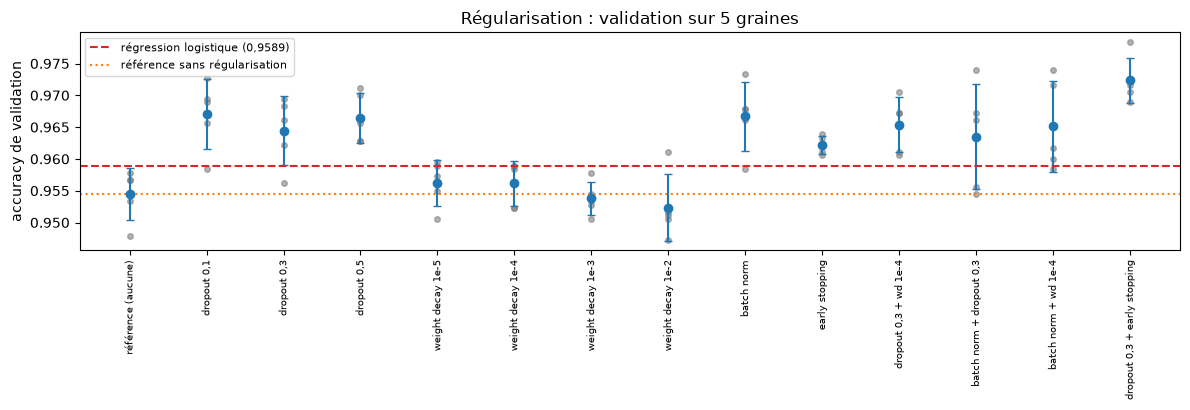

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.2))
noms = list(CONFIGS_REG)
for k, nom in enumerate(noms):
    d = reg_df[reg_df["config"] == nom]
    ax.scatter([k] * len(d), d["acc_val"], color="gray", alpha=0.6, s=16)
    ax.errorbar(k, d["acc_val"].mean(), yerr=d["acc_val"].std(), fmt="o", color="C0", capsize=3)
ax.axhline(0.9589, color="C3", linestyle="--", label="régression logistique (0,9589)")
ax.axhline(reg_df[reg_df["config"] == noms[0]]["acc_val"].mean(), color="C1", linestyle=":", label="référence sans régularisation")
ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, fontsize=7, rotation=90)
ax.set_ylabel("accuracy de validation")
ax.set_title("Régularisation : validation sur 5 graines")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Je constate que le dropout, la Batch Normalization et l'early stopping montent tous la validation autour de 0,962 à 0,972, au-dessus de la ligne orange (référence à 0,9545) et de la régression logistique (0,9589) pour la plupart. Le weight decay reste sur la ligne de la référence.

In [16]:
# Règle de 2.3 : une différence avec la référence est nette si elle dépasse 2 x le plus grand écart-type
ref = reg_df[reg_df["config"] == "référence (aucune)"]
for nom in list(CONFIGS_REG)[1:]:
    d = reg_df[reg_df["config"] == nom]
    diff = d["acc_val"].mean() - ref["acc_val"].mean()
    seuil = 2 * max(d["acc_val"].std(), ref["acc_val"].std())
    ecart_d = ((d["acc_train"] - d["acc_val"]).mean() - (ref["acc_train"] - ref["acc_val"]).mean()) * 100
    print(f"{nom:30s} validation {diff * 100:+.2f} pts (seuil {seuil * 100:.2f}, nette ? {'oui' if abs(diff) > seuil else 'non'})"
          f" | écart train-val {ecart_d:+.2f} pts")

dropout 0,1                    validation +1.25 pts (seuil 1.10, nette ? oui) | écart train-val -0.81 pts
dropout 0,3                    validation +1.00 pts (seuil 1.08, nette ? non) | écart train-val -0.74 pts
dropout 0,5                    validation +1.20 pts (seuil 0.82, nette ? oui) | écart train-val -1.54 pts
weight decay 1e-5              validation +0.18 pts (seuil 0.82, nette ? non) | écart train-val -0.09 pts
weight decay 1e-4              validation +0.17 pts (seuil 0.82, nette ? non) | écart train-val -0.05 pts
weight decay 1e-3              validation -0.07 pts (seuil 0.82, nette ? non) | écart train-val +0.10 pts
weight decay 1e-2              validation -0.21 pts (seuil 1.04, nette ? non) | écart train-val -0.48 pts
batch norm                     validation +1.22 pts (seuil 1.08, nette ? oui) | écart train-val -0.99 pts
early stopping                 validation +0.78 pts (seuil 0.82, nette ? non) | écart train-val -1.22 pts
dropout 0,3 + wd 1e-4          validation +1.0

Je remarque que 5 comparaisons sur 13 sont nettes selon ma règle de 2.3 : dropout 0,1, dropout 0,5, Batch Normalization, dropout 0,3 + weight decay et dropout 0,3 + early stopping, avec +1,1 à +1,8 point. Les autres (dropout 0,3 seul, early stopping seul, weight decay) sont des « non nettes », mais celles du dropout 0,3 et de l'early stopping sont tout près du seuil (+1,00 pour 1,08 ; +0,78 pour 0,82). Le **sens** est cohérent : toutes les configurations avec dropout, Batch Normalization ou early stopping montent de 0,8 à 1,8 point et réduisent l'écart train - validation. Comme je fais 13 comparaisons, quelques « nettes » peuvent venir du hasard ; c'est la cohérence d'ensemble qui me rassure.

Le **weight decay** ne change rien (de -0,2 à +0,2 point, écart train - validation inchangé) : la pénalité n'agit pas à ces valeurs, et à 1e-2 elle commence à gêner l'entraînement (train 0,9879).

### 4.2.2 Effet sur la stabilité

Je mesure la stabilité de deux façons : l'écart-type de l'accuracy de validation entre les 5 graines (déjà dans le tableau) et la fluctuation d'une époque à l'autre en fin d'entraînement (écart-type de l'accuracy de validation sur les 10 dernières époques, moyenné sur les graines). Plus ces valeurs sont petites, plus l'entraînement est stable.

In [17]:
stab = reg_df.groupby("config", sort=False).agg(ecart_type_graines=("acc_val", "std"),
                                                fluctuation_epoques=("fluct_val", "mean")) * 100
stab.columns = ["écart-type entre graines (pts)", "fluctuation entre époques (pts)"]
stab.round(2)

,écart-type entre graines (pts),fluctuation entre époques (pts)
config,,
référence (aucune),0.41,0.37
"dropout 0,1",0.55,0.45
"dropout 0,3",0.54,0.44
"dropout 0,5",0.39,0.37
weight decay 1e-5,0.36,0.37
weight decay 1e-4,0.36,0.36
weight decay 1e-3,0.26,0.45
weight decay 1e-2,0.52,0.66
batch norm,0.54,0.80


Je constate que la **stabilité entre graines** s'améliore peu : l'écart-type reste entre 0,3 et 0,8 point pour presque tout. Les combinaisons avec Batch Normalization sont même plus instables entre graines (0,71 à 0,83 point, contre 0,41 pour la référence). Seul l'early stopping seul est très stable (0,14 point), mais c'est en partie parce qu'on garde la meilleure époque.

La **fluctuation d'une époque à l'autre** augmente avec Batch Normalization (0,80 contre 0,37) et avec un weight decay fort (0,66). Je ne compare pas celle de l'early stopping aux autres : elle est calculée sur les 10 époques avant l'arrêt, où le réseau apprend encore, donc elle n'est pas comparable. La Batch Normalization donne de meilleurs scores mais un entraînement plus « nerveux » d'une époque à l'autre, et elle coûte plus de temps (3,3 s contre 2,0 s).

### 4.2.3 Configurations retenues pour la suite

Je retiens ces 3 configurations pour la suite, choisies sur la **moyenne de validation** et avec des mécanismes différents :

| Rang | Configuration | Validation (acc. ± écart-type) | F1 macro | Écart train - val |
|---|---|---|---|---|
| 1 | dropout 0,3 + early stopping | 0,9723 ± 0,0036 | 0,9703 | 1,60 pt |
| 2 | dropout 0,1 | 0,9670 ± 0,0055 | 0,9648 | 3,23 pts |
| 3 | batch norm | 0,9667 ± 0,0054 | 0,9648 | 3,05 pts |

Je précise trois points d'honnêteté :
- **Les rangs 2 et 3 ne sont pas séparables** de dropout 0,5 (0,9665) ni des combinaisons (0,9635 à 0,9654) : leurs écarts sont du niveau du bruit des graines (0,4 à 0,8 point). J'ai pris la meilleure moyenne de chaque famille, pas une « vraie » meilleure.
- Le rang 1 a un score de validation un peu **optimiste** : l'early stopping choisit l'époque avec la validation elle-même. Son avantage sur le dropout seul (+0,5 point) est sous le seuil de 2 écarts-types, donc je ne peux pas dire qu'il est meilleur.
- Le weight decay n'a rien apporté ; je ne le retiens pas.

Je garde aussi, comme références à comparer en 5.2, la régression logistique de la V1 et le réseau à une couche de la V1. Ces 3 configurations seront réentraînées avec le même réglage (3 couches ReLU, 128 neurones, Adam 3e-4) puis évaluées une seule fois sur le test.

In [18]:

# Configurations retenues pour la suite (Partie 5), réentraînables avec fit_reg(**params)
RETENUES = {
    "dropout 0,3 + early stopping": dict(dropout=0.3, early=True),
    "dropout 0,1": dict(dropout=0.1),
    "batch norm": dict(bn=True),
}
print(list(RETENUES))


['dropout 0,3 + early stopping', 'dropout 0,1', 'batch norm']


# Partie 5 : Visualisation et analyse des performances

> **Ce qui est demandé dans cette partie :**
> **5.1** Tracer l'évolution de la loss et de l'accuracy (ou du F1-score), sur l'entraînement et la validation, au cours des époques, pour suivre la convergence et détecter un surapprentissage ou un sous-apprentissage.
> **5.2** Évaluer une seule fois sur le test les 2 ou 3 configurations retenues et la référence de la Partie 1, comparer aux scores de validation, calculer et visualiser la matrice de confusion, et discuter les classes difficiles (la confusion est-elle plausible du point de vue des capteurs ?).

## 5.1 Courbes d'apprentissage

Je trace, pour le réseau de référence (sans régularisation) et pour les 3 configurations retenues en 4.2.3, la perte, l'accuracy (entraînement et validation) et le F1 macro de validation au fil des époques. Je ne réentraîne rien : j'utilise les historiques enregistrés en 4.1.3. Chaque courbe est la **moyenne sur les 5 graines**, avec une bande de ± 1 écart-type. Pour l'early stopping, les graines n'ont pas la même durée : je moyenne sur les graines encore actives à chaque époque, et la ligne verticale indique l'époque retenue (moyenne).

/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


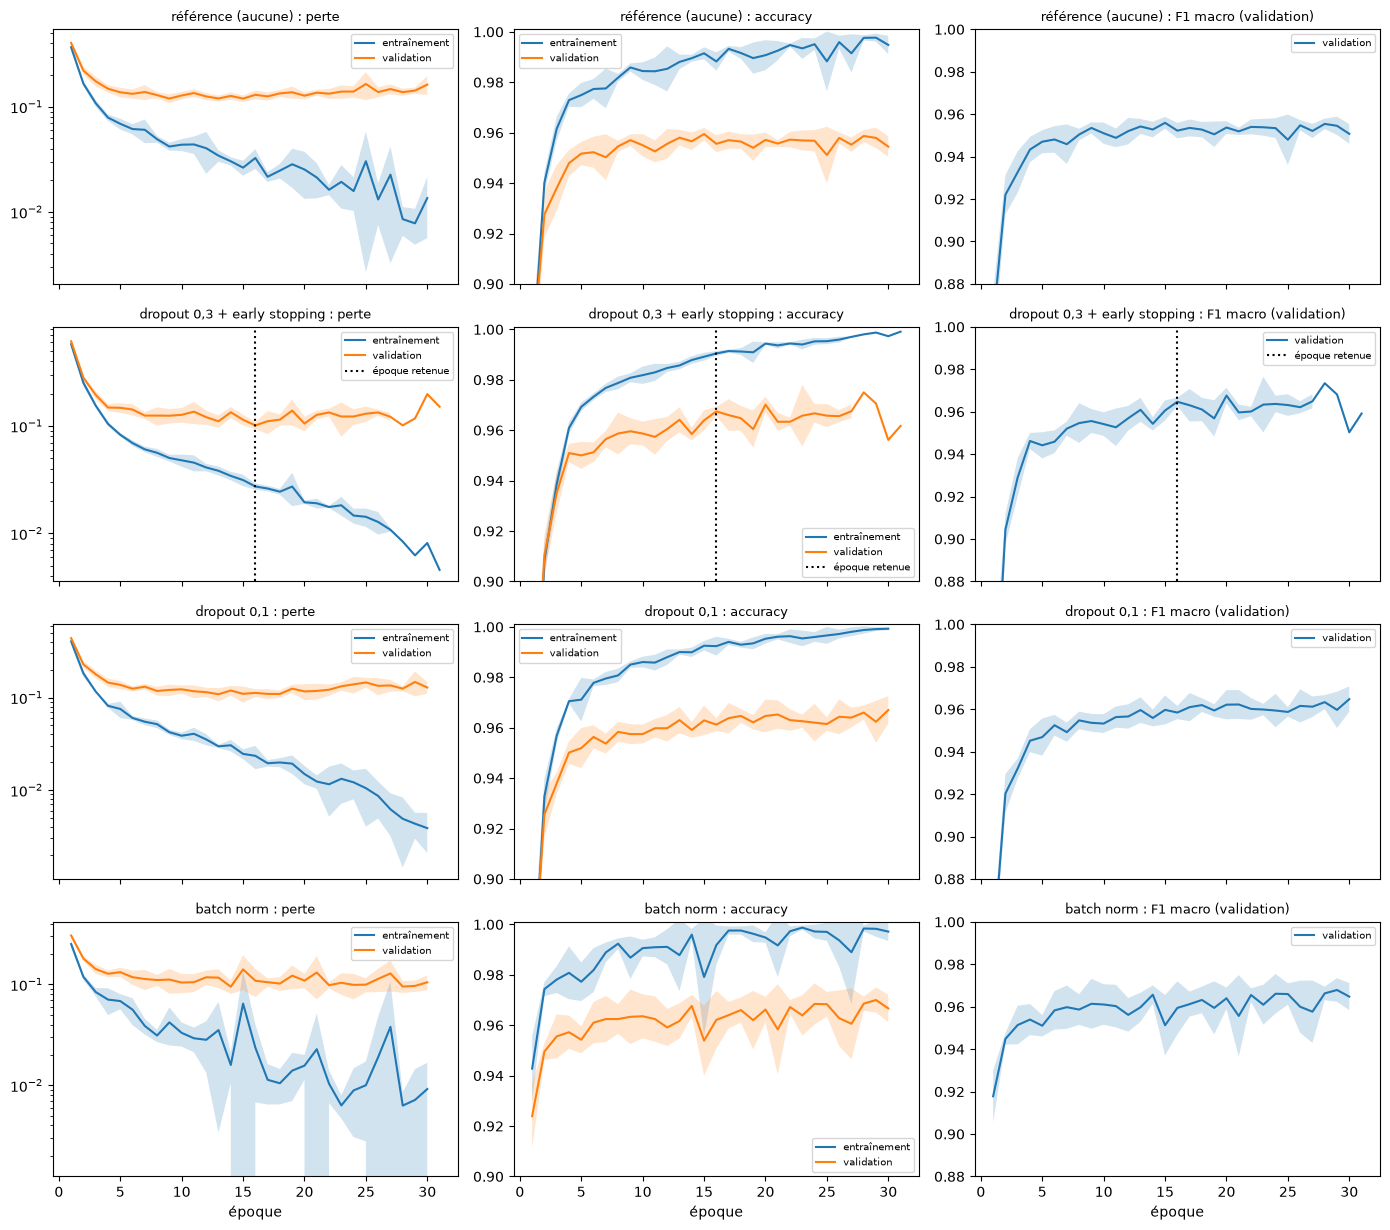

In [19]:
def courbe_moy(nom, cle):
    # Moyenne et écart-type sur les graines, époque par époque (les graines plus courtes sont ignorées après leur arrêt)
    h = [hist_reg[(nom, g)][cle] for g in SEEDS]
    n = max(len(x) for x in h)
    mat = np.full((len(h), n), np.nan)
    for k, x in enumerate(h):
        mat[k, :len(x)] = x
    return np.nanmean(mat, axis=0), np.nanstd(mat, axis=0, ddof=1)


a_tracer = ["référence (aucune)"] + list(RETENUES)
fig, axes = plt.subplots(len(a_tracer), 3, figsize=(14, 3.1 * len(a_tracer)), sharex="col")
for r, nom in enumerate(a_tracer):
    ep_ret = reg_df[reg_df["config"] == nom]["epoque"].mean()
    for c, (titre, paires) in enumerate([
            ("perte", [("train_loss", "entraînement"), ("val_loss", "validation")]),
            ("accuracy", [("train_acc", "entraînement"), ("val_acc", "validation")]),
            ("F1 macro (validation)", [("val_f1", "validation")])]):
        ax = axes[r, c]
        for cle, lab in paires:
            m, s = courbe_moy(nom, cle)
            x = np.arange(1, len(m) + 1)
            ax.plot(x, m, label=lab)
            ax.fill_between(x, m - s, m + s, alpha=0.2)
        if "early" in nom:
            ax.axvline(ep_ret, color="k", linestyle=":", label="époque retenue")
        ax.set_title(f"{nom} : {titre}", fontsize=9)
        if titre == "perte":
            ax.set_yscale("log")
        if titre == "accuracy":
            ax.set_ylim(0.9, 1.001)
        if titre.startswith("F1"):
            ax.set_ylim(0.88, 1.0)
        ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("époque")
plt.tight_layout()
plt.show()

Pour mettre des chiffres sur ce que je vois : je calcule pour chaque configuration l'époque où la perte de validation (moyenne sur les graines) est minimale, sa valeur à ce moment, et sa valeur à la dernière époque. Si la perte de validation remonte après son minimum, c'est le signe du surapprentissage.

In [20]:
lignes = []
for nom in a_tracer:
    mv, _ = courbe_moy(nom, "val_loss")
    mt, _ = courbe_moy(nom, "train_loss")
    macc, _ = courbe_moy(nom, "val_acc")
    k = int(np.argmin(mv))
    lignes.append({"configuration": nom, "époque du min. de perte val.": k + 1,
                   "perte val. minimale": round(mv[k], 3), "perte val. finale": round(mv[-1], 3),
                   "perte train finale": round(mt[-1], 4),
                   "époque du max. d'accuracy val.": int(np.argmax(macc)) + 1,
                   "accuracy val. max": round(macc.max(), 4), "accuracy val. finale": round(macc[-1], 4)})
pd.DataFrame(lignes).set_index("configuration")

/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,époque du min. de perte val.,perte val. minimale,perte val. finale,perte train finale,époque du max. d'accuracy val.,accuracy val. max,accuracy val. finale
configuration,,,,,,,
référence (aucune),15,0.119,0.162,0.0135,15,0.9595,0.9545
"dropout 0,3 + early stopping",16,0.101,0.151,0.0046,28,0.9750,0.9617
"dropout 0,1",13,0.109,0.128,0.0039,30,0.9670,0.9670
batch norm,14,0.095,0.105,0.0092,29,0.9700,0.9667


### 5.1.1 Observations

**Surapprentissage (référence sans régularisation).** Je remarque que la perte d'entraînement continue de baisser jusqu'à l'époque 30 (0,0135) alors que la perte de validation arrête de baisser vers l'époque 15 (minimum 0,119) puis remonte (0,162 à la fin). L'accuracy d'entraînement monte vers 99,5 % pendant que celle de validation reste bloquée autour de 95,5 % à 96 % : l'écart se creuse, c'est le surapprentissage. Je ne vois pas de sous-apprentissage : l'entraînement dépasse 98 % dès l'époque 8.

**Avec le dropout 0,1.** La perte de validation a son minimum au même endroit (époque 13), mais elle remonte moins (0,109 puis 0,128). Surtout, l'accuracy de validation continue de monter doucement jusqu'à l'époque 30 (0,967) au lieu de stagner. Le dropout n'empêche pas le surapprentissage de la perte, il le ralentit.

**Avec la Batch Normalization.** La perte de validation est la plus basse et la plus plate (0,095 au minimum, 0,105 à la fin). Par contre la courbe d'entraînement est très irrégulière : des pics aux époques 14, 21 et 27, avec de grandes bandes d'incertitude. Cela correspond à ce que je voyais en 4.2.2 (fluctuation plus forte avec Batch Normalization).

**Avec l'early stopping (dropout 0,3).** Les 3 courbes s'arrêtent en moyenne à l'époque 16 (ligne pointillée), proche du minimum de la perte de validation (époque 16). Attention à la lecture : après l'époque 16, la courbe ne représente plus que 1 ou 2 graines qui ont continué, donc le bruit et le saut à 0,975 vers l'époque 28 ne sont pas représentatifs.

**Un point que je n'attendais pas.** Pour les trois configurations régularisées, la perte de validation remonte après l'époque 13 à 16 alors que l'accuracy de validation, elle, ne baisse pas. Je l'interprète ainsi : le réseau devient trop sûr de lui sur ses erreurs (la perte punit fort une mauvaise réponse très confiante), sans faire plus d'erreurs. Cela explique aussi pourquoi arrêter vers l'époque 15 coûte peu en accuracy.

**Convergence.** Dans tous les cas, l'essentiel de l'apprentissage est fait en 5 à 10 époques ; les 20 suivantes n'apportent que de petits gains de validation, voire rien.

## 5.2 Évaluation finale et matrice de confusion

> **Demandé :** évaluer une seule fois sur le test les 2 ou 3 configurations retenues et la référence de la Partie 1, comparer aux scores de validation, calculer et visualiser la matrice de confusion sur le test, discuter les classes difficiles (la confusion est-elle plausible du point de vue des capteurs ?).

Mes étapes : 5.2.1 (évaluation sur le test), 5.2.2 (validation contre test), 5.2.3 (matrice de confusion), 5.2.4 (discussion).

### 5.2.1 Évaluation sur le test

**Règle que je respecte :** le test n'est évalué qu'**une seule fois par modèle**, dans une seule cellule. Je n'ai rien choisi à partir du test : les configurations viennent de la validation (4.2.3), et le modèle de la matrice de confusion est choisi sur la validation. Après avoir lu ces résultats, je ne change plus rien.

Les modèles sont entraînés comme pour la validation (sur les 16 volontaires d'entraînement, sans les 5 de validation) et le test est standardisé avec le scaler appris sur ces mêmes données d'entraînement.

Je réentraîne, avec les 5 graines, les 3 configurations de `RETENUES` (4.2.3). Je leur ajoute deux références : la régression logistique de la Partie 1 et le réseau à une couche de la V1 (ReLU, 128 neurones, Adam 3e-4), pour voir si la profondeur et la régularisation ont servi sur le test.

In [21]:
# ---- Seule cellule qui touche au test ----
from sklearn.linear_model import LogisticRegression

X_test_s = scaler.transform(test[feature_cols].to_numpy())
y_test = encoder.transform(test["Activity"])
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)


def predire_test(model):
    model.eval()
    with torch.no_grad():
        return model(X_test_t).argmax(dim=1).numpy()


resultats_test, preds_test = [], {}
for nom, params in RETENUES.items():
    for graine in SEEDS:
        model, h = fit_reg(seed=graine, **params)
        i = h["ep_retenue"]
        p = predire_test(model)
        preds_test[(nom, graine)] = p
        resultats_test.append({"config": nom, "graine": graine, "acc_val": h["val_acc"][i], "f1_val": h["val_f1"][i],
                               "acc_test": accuracy_score(y_test, p), "f1_test": f1_score(y_test, p, average="macro")})

# Référence V2 sans régularisation (3 couches ReLU) et réseau à une couche de la V1
for nom, acts_ou_params in [("référence 3 couches (sans régularisation)", None), ("réseau 1 couche (V1)", [R])]:
    for graine in SEEDS:
        if acts_ou_params is None:
            model, h = fit_reg(seed=graine)
        else:
            model, h = fit_profond(acts_ou_params, seed=graine)
        p = predire_test(model)
        preds_test[(nom, graine)] = p
        resultats_test.append({"config": nom, "graine": graine, "acc_val": h["val_acc"][-1], "f1_val": h["val_f1"][-1],
                               "acc_test": accuracy_score(y_test, p), "f1_test": f1_score(y_test, p, average="macro")})

# Régression logistique de la Partie 1
lr_ref = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_tr_s, y_tr)
pv, pt = lr_ref.predict(X_val_s), lr_ref.predict(X_test_s)
preds_test[("régression logistique", 0)] = pt
resultats_test.append({"config": "régression logistique", "graine": 0,
                       "acc_val": accuracy_score(y_val, pv), "f1_val": f1_score(y_val, pv, average="macro"),
                       "acc_test": accuracy_score(y_test, pt), "f1_test": f1_score(y_test, pt, average="macro")})
test_df = pd.DataFrame(resultats_test)
print("Évaluations sur le test :", len(test_df))

Évaluations sur le test : 26


### 5.2.2 Scores de validation et de test

In [22]:
lignes = []
for nom, d in test_df.groupby("config", sort=False):
    lignes.append({"configuration": nom,
                   "acc. validation": moy_std(d["acc_val"]), "acc. test": moy_std(d["acc_test"]),
                   "écart val - test (pts)": f"{(d['acc_val'].mean() - d['acc_test'].mean()) * 100:+.2f}",
                   "F1 macro validation": moy_std(d["f1_val"]), "F1 macro test": moy_std(d["f1_test"])})
pd.DataFrame(lignes).set_index("configuration")

,acc. validation,acc. test,écart val - test (pts),F1 macro validation,F1 macro test
configuration,,,,,
"dropout 0,3 + early stopping",0.9723 ± 0.0036,0.9406 ± 0.0008,+3.17,0.9703 ± 0.0039,0.9399 ± 0.0008
"dropout 0,1",0.9670 ± 0.0055,0.9407 ± 0.0044,+2.63,0.9648 ± 0.0060,0.9399 ± 0.0043
batch norm,0.9667 ± 0.0054,0.9482 ± 0.0054,+1.85,0.9648 ± 0.0064,0.9484 ± 0.0052
référence 3 couches (sans régularisation),0.9545 ± 0.0041,0.9379 ± 0.0023,+1.66,0.9507 ± 0.0046,0.9367 ± 0.0023
réseau 1 couche (V1),0.9592 ± 0.0030,0.9427 ± 0.0024,+1.66,0.9561 ± 0.0032,0.9422 ± 0.0023
régression logistique,0.9589 ± nan,0.9535 ± nan,+0.54,0.9552 ± nan,0.9530 ± nan


Je constate que **tous les réseaux perdent entre 1,7 et 3,2 points** de la validation au test, et la régression logistique seulement 0,5. Plus la validation était haute, plus la perte est grande (dropout 0,3 + early stopping : 0,9723 à 0,9406). Cela indique que mes choix sur la validation ont ajusté les modèles à ces 5 volontaires (ou que ces 5 volontaires étaient « faciles »). Les écarts-types sur 5 graines au test (0,1 à 0,5 point) sont petits devant ces écarts, donc la baisse est réelle et non due à la graine.

### 5.2.3 Matrice de confusion sur le test

Je prends la configuration retenue qui a la meilleure accuracy de **validation** (choix fait sans regarder le test) et je compare à la régression logistique. Les prédictions des 5 graines sont additionnées (chaque modèle n'a été évalué qu'une fois). Les lignes sont normalisées : chaque ligne montre où vont les fenêtres d'une vraie classe.

Meilleure configuration sur la validation : dropout 0,3 + early stopping 0.9723


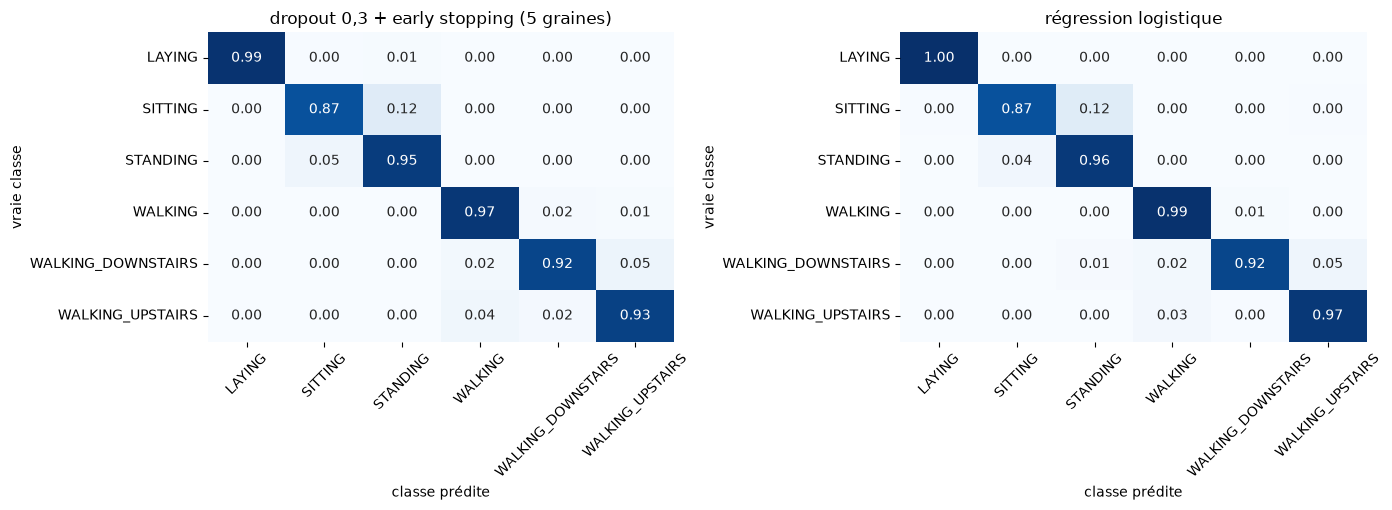

                    F1 réseau  F1 rég. logistique
LAYING                  0.993               0.997
SITTING                 0.905               0.914
STANDING                0.917               0.924
WALKING                 0.956               0.972
WALKING_DOWNSTAIRS      0.934               0.948
WALKING_UPSTAIRS        0.935               0.962

Confusions les plus fréquentes (vraie classe -> prédite) :
  SITTING -> STANDING : 12.2 %
  WALKING_DOWNSTAIRS -> WALKING_UPSTAIRS : 5.5 %
  STANDING -> SITTING : 4.9 %
  WALKING_UPSTAIRS -> WALKING : 4.3 %
  WALKING_DOWNSTAIRS -> WALKING : 2.5 %


In [23]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

val_moy = test_df[test_df["config"].isin(RETENUES)].groupby("config")["acc_val"].mean()
meilleur = val_moy.idxmax()
print("Meilleure configuration sur la validation :", meilleur, round(val_moy.max(), 4))

cm_net = sum(confusion_matrix(y_test, preds_test[(meilleur, g)], labels=range(6)) for g in SEEDS)
cm_lr = confusion_matrix(y_test, preds_test[("régression logistique", 0)], labels=range(6))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a, cm, titre in [(ax[0], cm_net, f"{meilleur} (5 graines)"), (ax[1], cm_lr, "régression logistique")]:
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=encoder.classes_, yticklabels=encoder.classes_, ax=a, cbar=False)
    a.set_title(titre)
    a.set_xlabel("classe prédite")
    a.set_ylabel("vraie classe")
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

f1_net = np.mean([f1_score(y_test, preds_test[(meilleur, g)], average=None) for g in SEEDS], axis=0)
f1_lr = f1_score(y_test, preds_test[("régression logistique", 0)], average=None)
print(pd.DataFrame({"F1 réseau": f1_net.round(3), "F1 rég. logistique": f1_lr.round(3)}, index=encoder.classes_).to_string())

pr = cm_net / cm_net.sum(axis=1, keepdims=True)
conf = sorted([(pr[i, j], encoder.classes_[i], encoder.classes_[j]) for i in range(6) for j in range(6) if i != j], reverse=True)[:5]
print("\nConfusions les plus fréquentes (vraie classe -> prédite) :")
for p, a, b in conf:
    print(f"  {a} -> {b} : {p * 100:.1f} %")

Je remarque que le réseau et la régression logistique se trompent aux mêmes endroits, avec le même motif en deux blocs (SITTING / STANDING, et les trois marches). Le réseau a un peu plus d'erreurs sur SITTING vers STANDING (12 %). La faiblesse en WALKING_DOWNSTAIRS que j'avais vue sur la validation (F1 le plus bas en 2.2) se retrouve ici sous forme de confusion avec WALKING_UPSTAIRS (5,5 %), ce qui répond à l'hypothèse que j'avais notée.

### 5.2.4 Discussion

**Ce que je constate sur le test.** Aucun réseau ne dépasse la régression logistique (0,9535) :

| Modèle | Validation | Test | Écart |
|---|---|---|---|
| régression logistique | 0,9589 | 0,9535 | 0,5 pt |
| batch norm | 0,9667 | 0,9482 | 1,9 pt |
| réseau 1 couche (V1) | 0,9592 | 0,9427 | 1,7 pt |
| dropout 0,1 | 0,9670 | 0,9407 | 2,6 pts |
| dropout 0,3 + early stopping | **0,9723** | 0,9406 | 3,2 pts |
| référence 3 couches sans régularisation | 0,9545 | 0,9379 | 1,7 pt |

Le classement de la validation ne se retrouve pas sur le test. La configuration qui était première sur la validation (dropout 0,3 + early stopping) est **avant-dernière** sur le test, et c'est elle qui a le plus grand écart (3,2 points). L'early stopping choisit l'époque sur la validation : son score de validation était optimiste, comme je l'avais écrit en 4.2.3. Les gains de la régularisation (+1 à +1,8 point sur la validation) ne se voient que très peu sur le test : de +0,3 point (dropout) à +1,0 point (batch norm) par rapport au même réseau sans régularisation. Seule la Batch Normalization reste au-dessus du réseau à une couche, et son écart avec la régression logistique (0,5 point) est plus petit que le double de son écart-type (1,1 point), donc non net.

**Ce que ça dit de mes choix.** Je ne peux pas affirmer qu'un réseau profond régularisé généralise mieux que la régression logistique sur ce jeu de données. Sélectionner sur la validation avec 5 volontaires m'a fait choisir des configurations un peu ajustées à ces 5 volontaires.

**Classes difficiles.** Comme en V1, ce sont **SITTING** (F1 0,905) et **STANDING** (0,917) : 12,2 % des fenêtres SITTING sont prédites STANDING (4,9 % l'inverse). Ensuite, **WALKING_DOWNSTAIRS vers WALKING_UPSTAIRS** (5,5 %) et **WALKING_UPSTAIRS vers WALKING** (4,3 %). LAYING est presque parfaite (0,993). La régression logistique est meilleure ou égale sur toutes les classes sauf une très légère différence sur SITTING (0,914 contre 0,905 pour le réseau), et surtout sur WALKING_UPSTAIRS (0,962 contre 0,935).

**Plausible pour les capteurs ?** Oui, je pense, sans pouvoir le démontrer avec ces données. Assis et debout sont deux postures immobiles : l'accélération due au mouvement est quasi nulle dans les deux cas et seule l'inclinaison du téléphone, donc la direction de la gravité, les distingue ; elle dépend de la façon de porter le téléphone. Allongé change complètement la direction de la gravité, d'où une classification presque parfaite. Les trois marches ont toutes un signal périodique et ne diffèrent que par des détails (intensité, composante verticale), donc monter et descendre se confondent entre eux et avec la marche plane.

**Limites.** 9 volontaires de test seulement : un écart de moins de 1 point entre deux modèles peut venir du choix de ces volontaires. Je ne conclus donc pas que la régression logistique est « meilleure » en général, mais que **les réseaux n'ont pas montré de gain** sur ces données, avec cette méthode.

# Partie 6 : Interprétabilité et réduction de dimension

> **Ce qui est demandé dans cette partie :**
> **6.1** Lire sur t-SNE et UMAP pour comprendre leur principe et leurs limites.
> **6.2** Les appliquer aux activations de la dernière couche cachée du réseau et, pour comparer, aux variables d'entrée brutes, pour voir comment le modèle projette les exemples dans un espace latent discriminant.
> **6.3** Comparer ces visualisations avec la matrice de confusion : les classes qui se chevauchent sont-elles les classes confondues ? Que le réseau a-t-il changé par rapport à l'entrée ? Quels enseignements sur la séparation des activités ? Quelles limites et précautions (perplexité, distances entre groupes, variabilité d'une exécution à l'autre) ?

Mes étapes : 6.1 (principe), 6.2.1 (activations), 6.2.2 (projections), 6.2.3 (mesures), 6.3.1 (lien avec la matrice de confusion), 6.3.2 (ce que le réseau a changé), 6.3.3 (limites et précautions).

## 6.1 Lecture et compréhension

Je résume ici ce que j'ai retenu des deux méthodes (t-SNE : van der Maaten et Hinton, 2008 ; UMAP : McInnes, Healy et Melville, 2018). Ce sont des résumés de lecture, à vérifier avec les articles originaux.

**Principe commun.** Elles placent chaque exemple dans un plan 2D de sorte que des exemples voisins dans l'espace de départ restent voisins sur le dessin. Elles ne sont pas supervisées : elles n'utilisent pas les classes, seulement les distances. Les couleurs que j'ajoute après servent à lire le résultat.

| | t-SNE | UMAP |
|---|---|---|
| Idée | Transformer les distances en probabilités de voisinage (lois gaussiennes dans l'espace de départ, loi de Student dans le plan) et minimiser leur écart (divergence de KL) | Construire un graphe de voisinage pondéré dans l'espace de départ puis chercher une disposition 2D qui garde ce graphe |
| Paramètre principal | **perplexité** (nombre de voisins « efficaces », souvent 5 à 50) | **n_neighbors** (taille du voisinage), **min_dist** (à quel point les points peuvent se tasser) |
| Vitesse | plus lent | plus rapide |
| Structure globale | surtout locale ; les distances entre groupes ne sont pas fiables | annoncée comme mieux conservée, mais cela se discute ; à ne pas sur-interpréter non plus |
| Variabilité | dépend de l'initialisation aléatoire | idem |

**Limites que je retiens.** (1) La taille d'un groupe et la distance entre deux groupes sur le dessin n'ont pas de sens précis. (2) Des groupes séparés peuvent être fabriqués par un mauvais paramètre, et des groupes proches peuvent être éloignés sur le dessin. (3) Deux exécutions différentes donnent deux dessins différents. (4) Il n'y a pas de projection d'un nouvel exemple sans recalcul (pour t-SNE standard). Je dois donc comparer plusieurs réglages avant de conclure.

## 6.2 Application sur le modèle

### 6.2.1 Activations de la dernière couche cachée

Je prends la configuration qui était la meilleure sur la validation (dropout 0,3 + early stopping, 3 couches de 128 neurones), avec la graine 0. Je la réentraîne (l'entraînement est reproductible) et je récupère la sortie de la dernière couche cachée, donc un vecteur de 128 nombres par fenêtre. Je projette ces vecteurs pour les **2947 fenêtres du test**, car je veux les comparer à la matrice de confusion du test. Je ne reviens sur aucun choix de modèle à partir de ces dessins : c'est de l'analyse, pas de la sélection.

In [24]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr
import umap

modele_proj, _ = fit_reg(seed=0, **RETENUES[meilleur])
modele_proj.eval()
with torch.no_grad():
    H_test = modele_proj.reseau[:-1](X_test_t).numpy()      # sortie de la dernière couche cachée
print("Activations de la dernière couche cachée :", H_test.shape, "| variables d'entrée :", X_test_s.shape)

pred0 = preds_test[(meilleur, 0)]                            # prédictions déjà calculées en 5.2 (graine 0)
erreurs = pred0 != y_test
print(f"Erreurs de ce modèle sur le test : {erreurs.sum()} sur {len(y_test)} ({erreurs.mean() * 100:.1f} %)")

Activations de la dernière couche cachée : (2947, 128) | variables d'entrée : (2947, 540)
Erreurs de ce modèle sur le test : 175 sur 2947 (5.9 %)


### 6.2.2 Projections t-SNE et UMAP

Je projette les deux espaces (les 540 variables d'entrée standardisées et les 128 activations) avec t-SNE (perplexité 30) et UMAP (n_neighbors 15, min_dist 0,1). Les points sont colorés par la vraie classe, et je marque d'une croix noire les fenêtres mal classées par le réseau.

/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


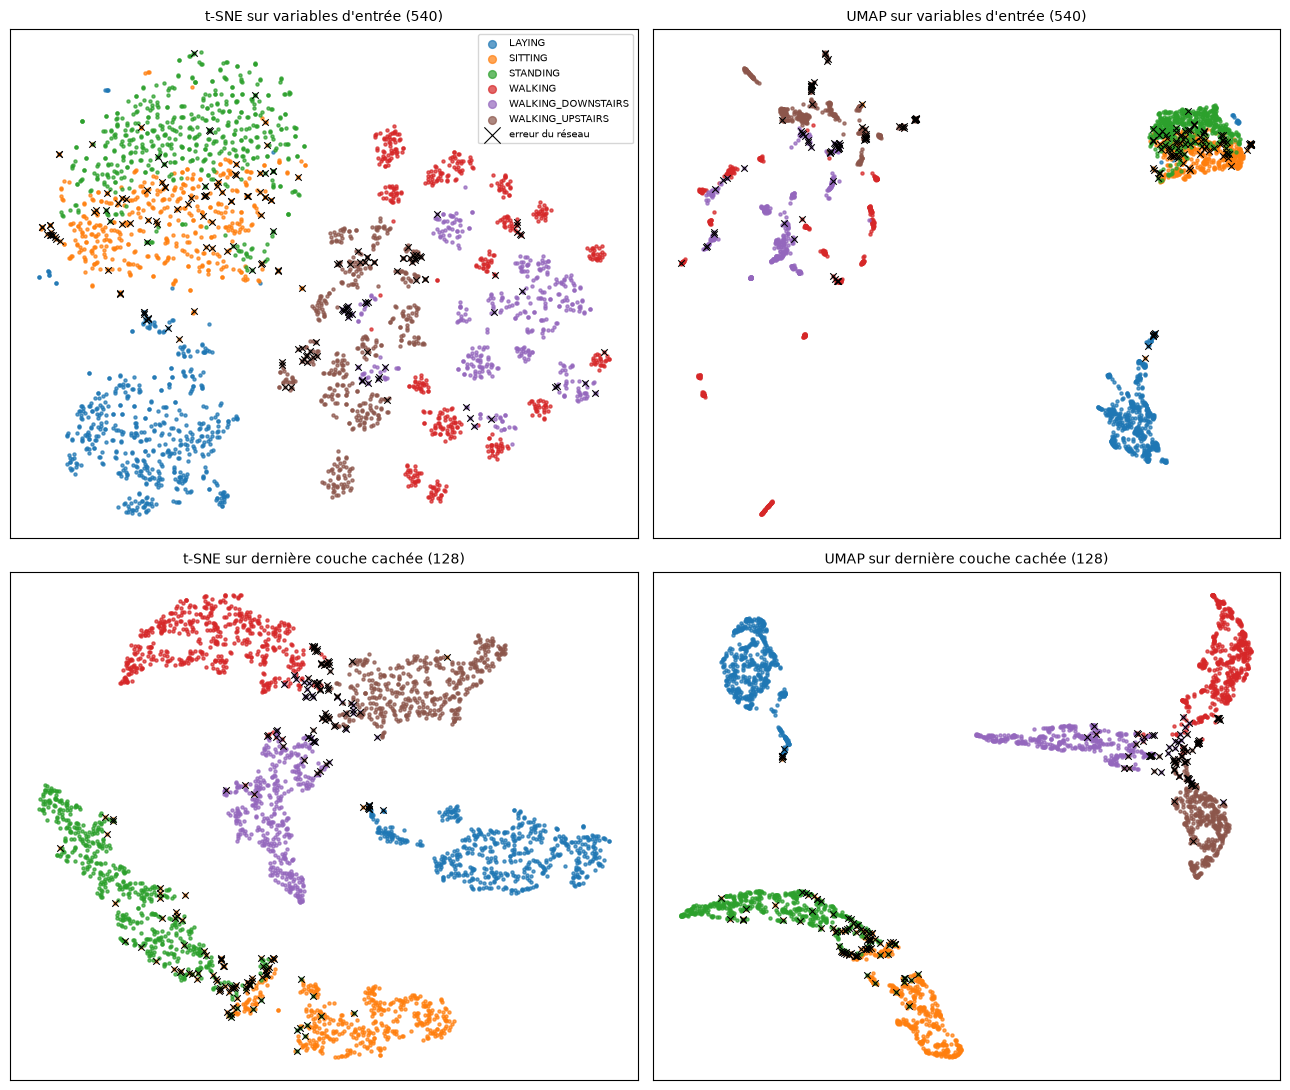

In [25]:
ESPACES = {"variables d'entrée (540)": X_test_s, "dernière couche cachée (128)": H_test}
emb = {}
for nom, X in ESPACES.items():
    emb[(nom, "t-SNE")] = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X)
    emb[(nom, "UMAP")] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(X)

couleurs = plt.cm.tab10(np.arange(6))


def tracer(ax, E, titre, marquer_erreurs=True):
    for c in range(6):
        m = y_test == c
        ax.scatter(E[m, 0], E[m, 1], s=5, color=couleurs[c], label=encoder.classes_[c], alpha=0.7)
    if marquer_erreurs:
        ax.scatter(E[erreurs, 0], E[erreurs, 1], s=22, marker="x", color="k", linewidths=0.8, label="erreur du réseau")
    ax.set_title(titre, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for r, nom in enumerate(ESPACES):
    for c, methode in enumerate(["t-SNE", "UMAP"]):
        tracer(axes[r, c], emb[(nom, methode)], f"{methode} sur {nom}")
axes[0, 0].legend(fontsize=7, markerscale=2.5, loc="best")
plt.tight_layout()
plt.show()

Je remarque que dans l'espace d'entrée les croix noires (erreurs) sont dispersées, surtout dans la zone SITTING / STANDING et dans les amas des marches. Dans la dernière couche cachée, elles sont **concentrées aux frontières** entre groupes : entre SITTING et STANDING, et à la jonction des trois marches. Les erreurs ne sont pas au hasard, elles sont là où les classes se touchent.

### 6.2.3 Mesures pour ne pas me fier qu'à l'œil

Je ne veux pas juger les dessins seulement à l'œil. Je calcule deux choses :
- le **coefficient de silhouette** (entre -1 et 1, plus il est grand plus les classes sont séparées) dans l'espace de départ complet (540 contre 128 dimensions) et dans le plan 2D ;
- une **matrice de mélange** : pour chaque fenêtre je regarde ses 10 plus proches voisins dans le plan et je note leur classe. Une ligne dit, pour une vraie classe, la proportion de voisins qui sont d'une autre classe. Je pourrai la comparer à la matrice de confusion.

In [26]:
def melange(E, y, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(E).kneighbors(E, return_distance=False)[:, 1:]
    Mx = np.zeros((6, 6))
    for c in range(6):
        v = y[idx[y == c]].ravel()
        Mx[c] = np.bincount(v, minlength=6) / len(v)
    return Mx


def top_paires(Mx, n=4):
    p = sorted([(Mx[i, j], encoder.classes_[i], encoder.classes_[j]) for i in range(6) for j in range(6) if i != j], reverse=True)[:n]
    return " ; ".join(f"{a}->{b} {v * 100:.0f}%" for v, a, b in p)


print("Silhouette dans l'espace de départ complet (vraies classes) :")
for nom, X in ESPACES.items():
    print(f"  {nom:32s} {silhouette_score(X, y_test):.3f}")

lignes = []
for (nom, methode), E in emb.items():
    Mx = melange(E, y_test)
    lignes.append({"espace": nom, "méthode": methode, "silhouette 2D": round(silhouette_score(E, y_test), 3),
                   "voisins de la bonne classe (%)": round(np.mean(np.diag(Mx)) * 100, 1),
                   "mélanges les plus forts": top_paires(Mx)})
pd.DataFrame(lignes).set_index(["espace", "méthode"])

Silhouette dans l'espace de départ complet (vraies classes) :
  variables d'entrée (540)         0.042
  dernière couche cachée (128)     0.547


silhouette 2D  \
espace                       méthode                  
variables d'entrée (540)     t-SNE            0.240   
                             UMAP             0.281   
dernière couche cachée (128) t-SNE            0.517   
                             UMAP             0.611   

                                      voisins de la bonne classe (%)  \
espace                       méthode                                   
variables d'entrée (540)     t-SNE                              94.5   
                             UMAP                               92.2   
dernière couche cachée (128) t-SNE                              94.0   
                             UMAP                               93.7   

                                                                mélanges les plus forts  
espace                       méthode                                                     
variables d'entrée (540)     t-SNE    SITTING->STANDING 14% ; STANDING->SITTING 13% ...  
                             UMAP     SITTING->STANDING 21% ; STANDING->SITTING 19% ...  
dernière couche cachée (128) t-SNE    SITTING->STANDING 11% ; STANDING->SITTING 9% ;...  
                             UMAP     SITTING->STANDING 11% ; STANDING->SITTING 10% ...

## 6.3 Analyse et comparaison

### 6.3.1 Lien avec la matrice de confusion

Je compare la matrice de mélange (t-SNE sur la dernière couche cachée) aux taux de confusion du réseau (matrice de 5.2, graine 0). Je regarde si les mêmes paires de classes ressortent, et je calcule la corrélation de rang (Spearman) entre les 30 valeurs hors diagonale des deux matrices.

Confusions les plus fréquentes du réseau : SITTING->STANDING 14% ; WALKING_UPSTAIRS->WALKING 6% ; WALKING_DOWNSTAIRS->WALKING_UPSTAIRS 4% ; STANDING->SITTING 3%
t-SNE  mélange le plus fort : SITTING->STANDING 11% ; STANDING->SITTING 9% ; WALKING_DOWNSTAIRS->WALKING_UPSTAIRS 4% ; WALKING_UPSTAIRS->WALKING_DOWNSTAIRS 3%
       corrélation de rang avec la matrice de confusion : 0.67 (p = 0.000)
UMAP   mélange le plus fort : SITTING->STANDING 11% ; STANDING->SITTING 10% ; WALKING_DOWNSTAIRS->WALKING_UPSTAIRS 4% ; WALKING_UPSTAIRS->WALKING_DOWNSTAIRS 3%
       corrélation de rang avec la matrice de confusion : 0.67 (p = 0.000)


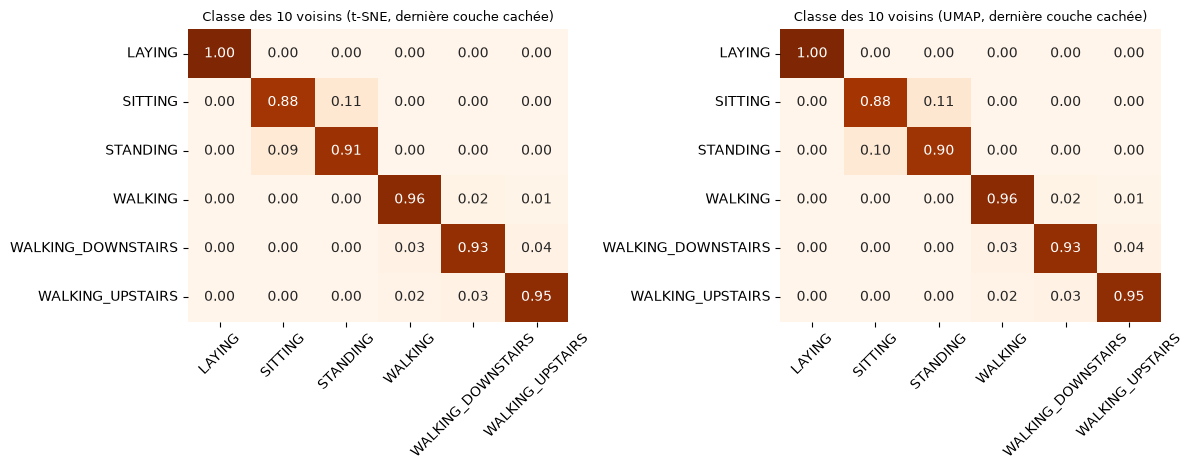

In [27]:
cm0 = confusion_matrix(y_test, pred0, labels=range(6))
taux_conf = cm0 / cm0.sum(axis=1, keepdims=True)
print("Confusions les plus fréquentes du réseau :", top_paires(taux_conf))
hors_diag = ~np.eye(6, dtype=bool)
for methode in ["t-SNE", "UMAP"]:
    Mx = melange(emb[("dernière couche cachée (128)", methode)], y_test)
    rho, pval = spearmanr(Mx[hors_diag], taux_conf[hors_diag])
    print(f"{methode:6s} mélange le plus fort : {top_paires(Mx)}")
    print(f"       corrélation de rang avec la matrice de confusion : {rho:.2f} (p = {pval:.3f})")

# Où sont les erreurs ? Part des erreurs dont la classe prédite est un voisin proche de la vraie classe dans le plan
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a, methode in zip(ax, ["t-SNE", "UMAP"]):
    sns.heatmap(melange(emb[("dernière couche cachée (128)", methode)], y_test), annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1,
                xticklabels=encoder.classes_, yticklabels=encoder.classes_, ax=a, cbar=False)
    a.set_title(f"Classe des 10 voisins ({methode}, dernière couche cachée)", fontsize=9)
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Je constate que les paires qui se mélangent dans le plan sont celles de la matrice de confusion : **SITTING / STANDING** en premier (11 % et 9 % de voisins de l'autre classe, contre 14 % et 3 % d'erreurs du réseau), puis **WALKING_DOWNSTAIRS / WALKING_UPSTAIRS** (4 % et 3 % de mélange, contre 4 % d'erreurs de DOWNSTAIRS vers UPSTAIRS). La corrélation de rang avec la matrice de confusion est de 0,67 pour t-SNE comme pour UMAP.

Des écarts à noter : le réseau confond SITTING vers STANDING (14 %) beaucoup plus souvent que l'inverse (3 %), alors que le mélange dans le plan est presque symétrique. Et WALKING_UPSTAIRS vers WALKING (6 % d'erreurs) ne ressort pas dans les mélanges du plan. Le plan montre quelles classes sont voisines, pas dans quel sens le réseau se trompe : la matrice de confusion reste l'outil à lire pour cela.

### 6.3.2 Ce que le réseau a changé par rapport à l'entrée

**Dans l'espace d'entrée**, j'observe que SITTING et STANDING sont mélangés dans une même région (très net en UMAP). LAYING est séparée des autres, et les trois marches forment de nombreux petits amas séparés (une hypothèse : un amas par volontaire, que je n'ai pas vérifiée). La silhouette dans l'espace complet est presque nulle (0,042) : les classes ne forment pas des nuages compacts.

**Dans la dernière couche cachée**, chaque activité devient un groupe compact (silhouette 0,547 dans l'espace complet, 0,52 à 0,61 en 2D). Les trois marches, qui étaient éclatées en petits amas, sont maintenant trois groupes qui se touchent au centre. SITTING et STANDING restent côte à côte mais forment deux groupes distincts, avec une zone de contact où se trouvent les croix noires.

**Point que je n'attendais pas.** La part des 10 voisins de la bonne classe est presque la même dans l'espace d'entrée et dans la couche cachée (94,5 % contre 94,0 % pour t-SNE). Au niveau local, l'entrée est déjà bien organisée. Ce que le réseau a surtout changé, c'est l'**organisation globale** : un seul bloc compact par classe au lieu d'amas éclatés, ce que mesure la silhouette (0,04 à 0,55). Je note aussi que ces voisins de test peuvent être des fenêtres consécutives du même volontaire, ce qui gonfle la pureté locale.

### 6.3.3 Limites et précautions : perplexité, distances, variabilité

Pour vérifier que mes conclusions ne dépendent pas d'un réglage, je refais les projections de la dernière couche cachée avec (a) trois perplexités (5, 30, 100), (b) trois graines aléatoires pour une même perplexité, (c) trois valeurs de n_neighbors pour UMAP. Je compare la silhouette 2D et la part de voisins de la bonne classe.

/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/martine/Desktop/Master-2-Malia/Cours-DEEP/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


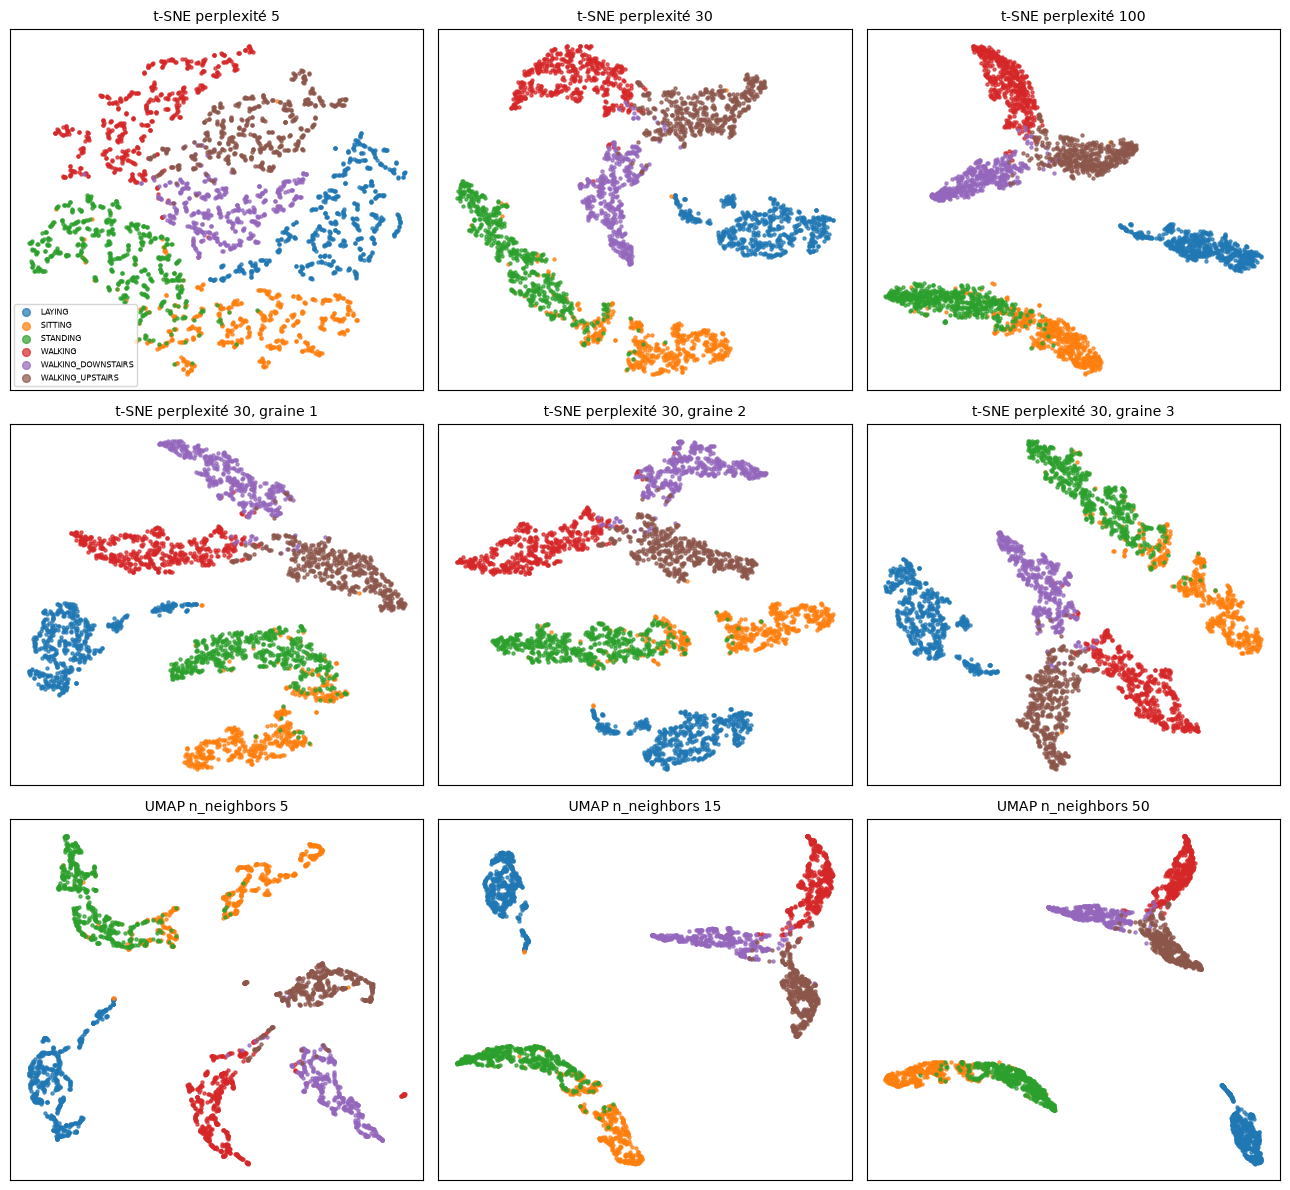

,silhouette 2D,voisins de la bonne classe (%),mélanges les plus forts
réglage,,,
t-SNE perplexité 5,0.325,93.9,SITTING->STANDING 11% ; STANDING->SITTING 9% ;...
t-SNE perplexité 30,0.517,94.0,SITTING->STANDING 11% ; STANDING->SITTING 9% ;...
t-SNE perplexité 100,0.596,93.7,SITTING->STANDING 12% ; STANDING->SITTING 10% ...
"t-SNE perplexité 30, graine 1",0.486,93.9,SITTING->STANDING 11% ; STANDING->SITTING 10% ...
"t-SNE perplexité 30, graine 2",0.489,93.9,SITTING->STANDING 11% ; STANDING->SITTING 9% ;...
"t-SNE perplexité 30, graine 3",0.493,94.1,SITTING->STANDING 11% ; STANDING->SITTING 9% ;...
UMAP n_neighbors 5,0.524,93.5,SITTING->STANDING 11% ; STANDING->SITTING 10% ...
UMAP n_neighbors 15,0.611,93.7,SITTING->STANDING 11% ; STANDING->SITTING 10% ...
UMAP n_neighbors 50,0.631,93.6,SITTING->STANDING 12% ; STANDING->SITTING 10% ...


In [28]:
H = ESPACES["dernière couche cachée (128)"]
variantes = []
for p in (5, 30, 100):
    variantes.append((f"t-SNE perplexité {p}", TSNE(n_components=2, perplexity=p, init="pca", random_state=0).fit_transform(H)))
for s in (1, 2, 3):
    variantes.append((f"t-SNE perplexité 30, graine {s}", TSNE(n_components=2, perplexity=30, init="random", random_state=s).fit_transform(H)))
for nn_ in (5, 15, 50):
    variantes.append((f"UMAP n_neighbors {nn_}", umap.UMAP(n_neighbors=nn_, min_dist=0.1, random_state=0).fit_transform(H)))

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
lignes = []
for ax, (nom, E) in zip(axes.ravel(), variantes):
    tracer(ax, E, nom, marquer_erreurs=False)
    Mx = melange(E, y_test)
    lignes.append({"réglage": nom, "silhouette 2D": round(silhouette_score(E, y_test), 3),
                   "voisins de la bonne classe (%)": round(np.mean(np.diag(Mx)) * 100, 1),
                   "mélanges les plus forts": top_paires(Mx, 3)})
axes[0, 0].legend(fontsize=6, markerscale=2.5)
plt.tight_layout()
plt.show()
pd.DataFrame(lignes).set_index("réglage")

**Perplexité.** Avec la perplexité 5 le t-SNE éclate chaque classe en petits morceaux et les classes se touchent (silhouette 2D 0,33) ; à 30 et à 100 les groupes sont plus nets (0,52 et 0,60). La part de voisins de la bonne classe ne change presque pas (93,7 à 94,0 %) : la silhouette 2D dépend beaucoup du réglage, alors que la structure locale est stable.

**Variabilité d'une exécution à l'autre.** Avec 3 graines différentes à perplexité 30, la silhouette varie peu (0,486 à 0,493) mais **le dessin change complètement** : les groupes ne sont pas à la même place ni orientés pareil. Je ne peux donc pas dire « LAYING est à gauche ». Ce qui reste d'un dessin à l'autre : les 6 groupes, et les paires qui se touchent (SITTING / STANDING, les trois marches).

**UMAP.** Les trois valeurs de n_neighbors donnent des groupes nets, mais l'image change : avec n_neighbors 5, SITTING et STANDING forment deux groupes bien séparés, alors qu'avec 50 ils forment une bande continue. Le « degré de séparation » de SITTING et STANDING dépend donc du réglage. C'est précisément la paire que la matrice de confusion montre comme difficile : je fais plus confiance à la matrice qu'à la distance sur le dessin.

**Les distances entre groupes** n'ont pas de sens fiable : LAYING est tantôt très loin, tantôt plus proche des autres groupes selon l'exécution.

**Précautions que je retiens :** (1) tester plusieurs réglages ; (2) ne jamais lire les distances ni les tailles ; (3) mesurer plutôt que regarder ; (4) rappeler que les fenêtres du test se chevauchent (50 %) et que des voisins du même volontaire gonflent la pureté locale, donc les 94 % ne sont pas une accuracy.

### 6.3.4 Conclusion de la Partie 6

- Le réseau sépare nettement les 6 activités dans sa dernière couche cachée. Les confusions qui restent se placent à deux endroits : la frontière **SITTING / STANDING** et la jonction des **trois marches**. Ce sont aussi les confusions de la matrice de confusion (corrélation de rang 0,67 entre le mélange dans le plan et les taux d'erreur).
- Les groupes se retrouvent d'un réglage à l'autre, mais leur **position, leur taille et leur distance** changent. Je les lis comme « ces classes sont voisines ou séparées », jamais comme « cette distance vaut X ».
- Mes mesures chiffrées sont sensibles au réglage (la silhouette 2D du t-SNE varie de 0,33 à 0,60 selon la perplexité), donc je ne les compare qu'entre espaces avec le même réglage.
- Je n'ai pas vérifié que le classement entre espace d'entrée et dernière couche cachée tient pour tous les réglages : je l'ai fait seulement pour t-SNE (perplexité 30) et UMAP (n_neighbors 15).
- Cohérence avec la 5.2 : ce réseau avait pourtant un score de test inférieur à la régression logistique. Ces visualisations montrent que ce n'est pas un échec de séparation globale : les groupes sont nets, et les erreurs restent aux frontières entre classes déjà difficiles.

# Partie 7 : Ouvertures possibles (bonus)

> **Ce qui est proposé :** automatiser la recherche d'hyperparamètres ; analyser l'importance des variables (importance ou ablation) ; tester d'autres normalisations (LayerNorm, etc.) ; entraîner un réseau convolutif ou récurrent sur les signaux bruts (point facultatif).

Je traite **deux pistes**, qui prolongent des résultats précédents et ne demandent pas de nouvelles données :
- **7.1 Normalisation** : la Batch Normalization était instable d'une époque à l'autre en 4.2.2. Je teste LayerNorm.
- **7.2 Importance des variables** : en 6.3 les confusions se concentraient sur SITTING / STANDING. Je cherche quels groupes de variables comptent pour le réseau.

Je ne traite pas la recherche automatique d'hyperparamètres (elle s'ajusterait aux 5 volontaires de validation, le piège de 5.2) ni les signaux bruts (absents de mes fichiers, il faudrait les télécharger sur le dépôt UCI). Tout se fait sur la **validation** : le test a déjà servi en 5.2 et je n'y retouche pas.

## 7.1 Une autre normalisation : LayerNorm

La Batch Normalization normalise chaque neurone sur le mini-batch ; elle dépend donc des autres exemples du batch, ce qui peut rendre l'entraînement irrégulier. **LayerNorm** normalise, pour chaque exemple, l'ensemble des neurones d'une couche : elle ne dépend pas du batch. Je compare, sur le réseau à 3 couches ReLU de 128 neurones (Adam 3e-4, 30 époques, 5 graines) : aucune normalisation, Batch Normalization, LayerNorm. Même méthode que 4.1 (règle de 2.3, stabilité entre graines et entre époques).

In [29]:
class MLPNorm(nn.Module):
    # 3 x [Linear -> (normalisation) -> ReLU] puis Linear de sortie
    def __init__(self, n_entrees, largeur, n_classes, norme=None, n_couches=3):
        super().__init__()
        couches, n_in = [], n_entrees
        for _ in range(n_couches):
            couches.append(nn.Linear(n_in, largeur))
            if norme == "batch":
                couches.append(nn.BatchNorm1d(largeur))
            elif norme == "layer":
                couches.append(nn.LayerNorm(largeur))
            couches.append(nn.ReLU())
            n_in = largeur
        couches.append(nn.Linear(n_in, n_classes))
        self.reseau = nn.Sequential(*couches)

    def forward(self, x):
        return self.reseau(x)


def fit_norme(norme, seed, lr=3e-4):
    torch.manual_seed(seed)
    model = MLPNorm(N_ENTREES, 128, N_CLASSES, norme)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    for _ in range(N_EPOCHS):
        train_epoch(model, loader, opt, lossfn)
        tl, ta, _ = evaluate(model, train_eval_loader, lossfn)
        vl, va, vf = evaluate(model, val_loader, lossfn)
        for cle, val in zip(hist, (tl, ta, vl, va, vf)):
            hist[cle].append(val)
    return model, hist


NORMES = {"aucune": None, "BatchNorm": "batch", "LayerNorm": "layer"}
lignes = []
for nom, norme in NORMES.items():
    for graine in SEEDS:
        t0 = time.time()
        _, h = fit_norme(norme, graine)
        lignes.append({"norme": nom, "graine": graine, "acc_train": h["train_acc"][-1], "acc_val": h["val_acc"][-1],
                       "f1_val": h["val_f1"][-1], "fluct_val": float(np.std(h["val_acc"][-10:])),
                       "temps_s": time.time() - t0})
norme_df = pd.DataFrame(lignes)

resume = []
for nom, d in norme_df.groupby("norme", sort=False):
    resume.append({"normalisation": nom, "acc. entraînement": moy_std(d["acc_train"]), "acc. validation": moy_std(d["acc_val"]),
                   "F1 macro validation": moy_std(d["f1_val"]),
                   "écart train - val (pts)": f"{(d['acc_train'] - d['acc_val']).mean() * 100:.2f}",
                   "fluctuation entre époques (pts)": f"{d['fluct_val'].mean() * 100:.2f}",
                   "temps (s)": f"{d['temps_s'].mean():.1f}"})
display(pd.DataFrame(resume).set_index("normalisation"))

for a, b in [("LayerNorm", "aucune"), ("BatchNorm", "aucune"), ("LayerNorm", "BatchNorm")]:
    sa, sb = [norme_df[norme_df["norme"] == n]["acc_val"] for n in (a, b)]
    diff, seuil = sa.mean() - sb.mean(), 2 * max(sa.std(), sb.std())
    print(f"{a:9s} contre {b:9s} : {diff * 100:+.2f} pts (seuil {seuil * 100:.2f}) | nette ? {'oui' if abs(diff) > seuil else 'non'}")

,acc. entraînement,acc. validation,F1 macro validation,écart train - val (pts),fluctuation entre époques (pts),temps (s)
normalisation,,,,,,
aucune,0.9948 ± 0.0037,0.9545 ± 0.0041,0.9507 ± 0.0046,4.03,0.37,1.9
BatchNorm,0.9972 ± 0.0037,0.9667 ± 0.0054,0.9648 ± 0.0064,3.05,0.80,3.1
LayerNorm,1.0000 ± 0.0000,0.9621 ± 0.0055,0.9580 ± 0.0064,3.79,0.34,2.5


LayerNorm contre aucune    : +0.77 pts (seuil 1.09) | nette ? non
BatchNorm contre aucune    : +1.22 pts (seuil 1.08) | nette ? oui
LayerNorm contre BatchNorm : -0.46 pts (seuil 1.09) | nette ? non


### 7.1.1 Observations

Je constate que **LayerNorm n'est pas nettement différente** des deux autres : +0,77 point contre l'absence de normalisation (seuil 1,09) et -0,46 point contre la BatchNorm (seuil 1,09). Seule la BatchNorm est nette contre l'absence de normalisation (+1,22 pour un seuil de 1,08, tout près du seuil comme en 4.2.1).

Sur l'entraînement, LayerNorm atteint **100 %** (écart-type nul) : le réseau mémorise complètement le train, et l'écart train - validation reste à 3,8 points, comme sans normalisation (4,0) et plus qu'avec BatchNorm (3,1). Je n'ai donc pas de réduction du surapprentissage avec LayerNorm.

Ce qui change : la **fluctuation d'une époque à l'autre** est de 0,34 point avec LayerNorm, comme sans normalisation (0,37), contre 0,80 avec BatchNorm. C'est bien l'idée de départ (LayerNorm ne dépend pas du batch). Ce sont des moyennes sur 5 graines, sans écart-type. Le temps est aussi plus faible que pour la BatchNorm (2,5 s contre 3,1 s).

## 7.2 Importance des variables par groupes

Je mesure l'importance par **permutation** : sur la validation, je mélange au hasard les valeurs d'un groupe de variables entre les fenêtres (le même mélange pour toutes les variables du groupe, pour garder leurs liens entre elles), et je regarde de combien baisse l'accuracy du réseau. Plus elle baisse, plus le réseau s'appuie sur ce groupe. Je travaille par **groupes** et non variable par variable, car les 540 variables sont très corrélées : mélanger une seule variable ne dirait presque rien (ses « jumelles » la remplaceraient).

Groupes : la famille du signal (par exemple `BodyAcc` : accélération du corps, `GravityAcc` : composante de gravité, `BodyGyro` : gyroscope, avec ou sans `Jerk` et `Mag`) et les variables `angle(...)`. Je regarde la baisse de l'accuracy et la baisse du F1 de SITTING et de STANDING. Je prends la configuration retenue en première sur la validation, avec les 5 graines, et 5 mélanges par groupe.

In [30]:
def famille(nom):
    if nom.startswith("angle"):
        return "angle"
    return nom.split("-")[0][1:].replace("BodyBody", "Body")      # on enlève le préfixe t / f


def capteur(nom):
    if nom.startswith("angle"):
        return "angle"
    return "gyroscope" if "Gyro" in nom else "accéléromètre"


fam = np.array([famille(c) for c in feature_cols])
cap = np.array([capteur(c) for c in feature_cols])
dom = np.array(["fréquence" if (c[0] == "f") else ("temps" if c[0] == "t" else "angle") for c in feature_cols])
print(pd.Series(fam).value_counts().to_string())

BodyAcc            119
BodyAccJerk        119
BodyGyro           119
GravityAcc          40
BodyGyroJerk        40
BodyAccMag          24
BodyAccJerkMag      24
BodyGyroMag         24
BodyGyroJerkMag     24
angle                7


In [31]:
SITTING, STANDING = list(encoder.classes_).index("SITTING"), list(encoder.classes_).index("STANDING")
config_best = RETENUES[meilleur]
rng = np.random.RandomState(0)


def predire_val(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32)).argmax(dim=1).numpy()


def scores(p):
    f = f1_score(y_val, p, average=None, labels=range(6))
    return accuracy_score(y_val, p), f[SITTING], f[STANDING]


groupages = {"famille de signal": fam, "capteur": cap, "domaine": dom}
lignes = []
for graine in SEEDS:
    model, _ = fit_reg(seed=graine, **config_best)
    base = scores(predire_val(model, X_val_s))
    for nom_groupage, etiq in groupages.items():
        for g in sorted(set(etiq)):
            idx = np.where(etiq == g)[0]
            chutes = []
            for _ in range(5):
                perm = rng.permutation(len(X_val_s))
                Xp = X_val_s.copy()
                Xp[:, idx] = X_val_s[perm][:, idx]
                chutes.append(np.array(base) - np.array(scores(predire_val(model, Xp))))
            c = np.mean(chutes, axis=0)
            lignes.append({"groupage": nom_groupage, "groupe": g, "nb_variables": len(idx), "graine": graine,
                           "chute_acc": c[0] * 100, "chute_f1_sitting": c[1] * 100, "chute_f1_standing": c[2] * 100})
imp_df = pd.DataFrame(lignes)
tab = imp_df.groupby(["groupage", "groupe"]).agg(nb_variables=("nb_variables", "first"),
        chute_acc=("chute_acc", "mean"), ecart_type=("chute_acc", "std"),
        chute_f1_sitting=("chute_f1_sitting", "mean"), chute_f1_standing=("chute_f1_standing", "mean")).round(2)
tab = tab.sort_values(["groupage", "chute_acc"], ascending=[True, False])
tab.columns = ["nb variables", "baisse d'accuracy (pts)", "écart-type (pts)", "baisse F1 SITTING (pts)", "baisse F1 STANDING (pts)"]
tab

nb variables  baisse d'accuracy (pts)  \
groupage          groupe                                                   
capteur           accéléromètre             326                    70.84   
                  gyroscope                 207                    21.44   
                  angle                       7                     1.71   
domaine           temps                     248                    60.44   
                  fréquence                 285                    28.96   
                  angle                       7                     1.70   
famille de signal GravityAcc                 40                    32.06   
                  BodyAcc                   119                     9.66   
                  BodyAccJerk               119                     7.80   
                  BodyGyro                  119                     7.42   
                  BodyAccMag                 24                     3.50   
                  BodyGyroJerk               40                     2.03   
                  angle                       7                     1.81   
                  BodyAccJerkMag             24                     1.07   
                  BodyGyroJerkMag            24                     0.56   
                  BodyGyroMag                24                     0.55   

                                   écart-type (pts)  baisse F1 SITTING (pts)  \
groupage          groupe                                                       
capteur           accéléromètre                1.11                    56.72   
                  gyroscope                    1.70                    41.99   
                  angle                        0.43                     4.63   
domaine           temps                        2.43                    74.76   
                  fréquence                    3.16                    12.65   
                  angle                        0.48                     4.61   
famille de signal GravityAcc                   1.30                    47.11   
                  BodyAcc                      0.86                     2.03   
                  BodyAccJerk                  0.98                     4.17   
                  BodyGyro                     0.64                    16.39   
                  BodyAccMag                   0.51                     0.69   
                  BodyGyroJerk                 0.74                     6.60   
                  angle                        0.60                     4.97   
                  BodyAccJerkMag               0.25                     0.54   
                  BodyGyroJerkMag              0.33                     1.32   
                  BodyGyroMag                  0.25                     1.00   

                                   baisse F1 STANDING (pts)  
groupage          groupe                                     
capteur           accéléromètre                       66.22  
                  gyroscope                           28.81  
                  angle                                3.28  
domaine           temps                               55.42  
                  fréquence                           33.00  
                  angle                                3.32  
famille de signal GravityAcc                          27.95  
                  BodyAcc                              9.94  
                  BodyAccJerk                         12.96  
                  BodyGyro                            12.26  
                  BodyAccMag                           0.77  
                  BodyGyroJerk                         4.99  
                  angle                                3.59  
                  BodyAccJerkMag                       0.49  
                  BodyGyroJerkMag                      1.11  
                  BodyGyroMag                          1.36

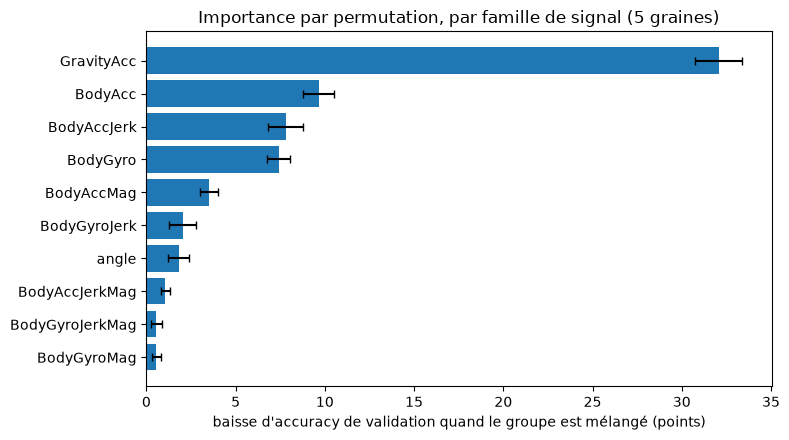

In [32]:
d = imp_df[imp_df["groupage"] == "famille de signal"].groupby("groupe")["chute_acc"].agg(["mean", "std"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(d.index, d["mean"], xerr=d["std"], color="C0", capsize=3)
ax.set_xlabel("baisse d'accuracy de validation quand le groupe est mélangé (points)")
ax.set_title("Importance par permutation, par famille de signal (5 graines)")
plt.tight_layout()
plt.show()

### 7.2.1 Observations

**Le groupe qui compte le plus est `GravityAcc`** (composante de gravité de l'accéléromètre) : le mélanger fait baisser l'accuracy de 32 points (± 1,3) avec seulement 40 variables. Les familles `BodyAcc` (119 variables), `BodyAccJerk` (119) et `BodyGyro` (119) font baisser l'accuracy de 7 à 10 points seulement. Par variable, `GravityAcc` pèse donc beaucoup plus. Les familles `Mag` et `GyroJerk` comptent peu (moins de 4 points), tout comme le groupe `angle` (1,8 point, 7 variables).

**Lien avec SITTING / STANDING.** Mélanger `GravityAcc` fait chuter le F1 de SITTING de 47 points et celui de STANDING de 28 points. C'est cohérent avec mon explication : ces deux postures immobiles ne diffèrent que par l'inclinaison du téléphone, donc par la gravité. Le gyroscope (mouvement de rotation) est moins décisif pour ces deux classes, mais il compte aussi (`BodyGyro` : 16 points de baisse pour SITTING).

**Par capteur et par domaine.** Les variables de l'accéléromètre comptent plus (baisse de 71 points) que celles du gyroscope (21 points). Le domaine « temps » (60 points) pèse plus que « fréquence » (29 points), mais attention : la gravité n'existe que dans le domaine temps, donc ces deux résultats sont en partie le même que celui de `GravityAcc`.

**Précautions.** (1) Un gros groupe mélangé détruit plus d'information qu'un petit : je ne compare donc pas directement les tailles de groupes. (2) Mélanger entre fenêtres crée des combinaisons de variables qui n'existent pas, ce qui peut exagérer la baisse. (3) Les variables sont corrélées : un groupe peu important peut être remplacé par un autre. (4) Une baisse forte dit que le réseau **utilise** un groupe, pas qu'il a « raison » de l'utiliser.

### 7.3 Conclusion du bonus

- **LayerNorm** n'apporte pas de gain net de généralisation : sa validation (0,9621) n'est pas nettement différente de la BatchNorm (0,9667) ni de l'absence de normalisation (0,9545), et elle surapprend jusqu'à 100 % en entraînement. Son intérêt est la **stabilité d'une époque à l'autre**, aussi bonne que sans normalisation, alors que la BatchNorm fluctue davantage. Je n'ai pas évalué ces variantes sur le test (il a déjà servi en 5.2).
- **Importance des variables** : le réseau s'appuie très fortement sur les variables liées à la **gravité**, et c'est cohérent avec ce que j'avançais en 5.2 pour SITTING / STANDING (la gravité donne l'inclinaison du téléphone). C'est un appui sérieux, mais pas une preuve : les mélanges produisent des données irréalistes et les variables sont corrélées.
- **Ce que je n'ai pas fait** : recherche automatique d'hyperparamètres (risque d'ajustement à la validation) et signaux bruts (données absentes de mes fichiers).